# Task 4 – Teil 5: Lastflussumkehr

**Ausgangspunkt:** das Netz am Ende von Teil 4. Es umfasst:
- CIGRE-MV ohne DER (Baseline des Arbeitsauftrags) mit dem ausgelegten Ortsnetz an Bus 12,
- rONT-Regelung und Backup-Plan aus Teil 3b,
- Windpark (30 MW) an Bus 1 und PV-Freiflächenanlage (10 MWp) an Bus 12 aus Teil 4a,
- PV-Haushalte im Ortsnetz, Variante „heute“ (8,3 % der Haushaltslast mit Profil P25, 6,7 % mit S25) aus Teil 4a.

Voraussetzung: `Task4-4a_Erzeugung_Anschluss.ipynb` wurde ausgeführt (Simulation `w4_kombi_W1_P12`).

### Anforderungen aus dem Arbeitsauftrag (Abschnitt 5)

> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1–S3. Werten Sie Wirkleistungsflüsse an geeigneten Leitungen, Netzkuppelstellen und Transformatoren aus. Erklären Sie anhand der verwendeten pandapower-Ergebnisfelder deren Vorzeichen und leiten Sie daraus ab, wann ein Leistungsfluss seine Richtung wechselt. Untersuchen Sie, welche Erzeugungs- und Lastbedingungen die Umkehr auslösen, wie stark und wie häufig sie auftritt und welche Folgen sich für Spannungen, Auslastungen und die Regelung des Ortsnetztransformators ergeben. Zeitreihen, Dauerlinien oder eine räumliche Darstellung der Flüsse können den Vergleich unterstützen.*

| Anforderung | wo |
|---|---|
| Wirkleistungsflüsse an Leitungen, Netzkuppelstelle (110 kV) und Trafos | Abschnitt 3 und 4 |
| Vorzeichen der pandapower-Ergebnisfelder, Kriterium für den Richtungswechsel | Abschnitt 2 |
| alle Schalterstellungen S1–S3 | Abschnitt 4 |
| auslösende Erzeugungs- und Lastbedingungen | Abschnitt 3 (Normalzustand) |
| Stärke und Häufigkeit der Umkehr | Abschnitt 3, 4 und 7 (Dauerlinien) |
| Folgen für Spannungen und Auslastungen | Abschnitt 5 |
| Folgen für die rONT-Regelung | Abschnitt 6 |
| Zeitreihen, Dauerlinien, räumliche Darstellung | Abschnitt 3, 7 und 8 |

### Aufbau

1. Netz am Ende von Teil 4 erstellen
2. Vorzeichen der Ergebnisfelder
3. Normalzustand: Wo kehrt sich der Leistungsfluss um, und welche Muster gibt es?
4. Alle Schalterstellungen: Änderung der Leistungsflüsse gegenüber dem Normalzustand
5. Folgen für Spannungen und Auslastungen
6. Folgen für die rONT-Regelung
7. Dauerlinien
8. Räumliche Darstellung der Flüsse
9. Rückspeisung im Ortsnetz
10. Zusatz: Ausfall eines 110/20-kV-Transformators
11. Ergebnis

## Importe

In [ ]:
import copy

import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import netplan
from elements import Diagram
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

sim.ONLY_RUN_IF_CHANGED = True
PLAN_MARKER = [("orange", 0.95, "Planungsband 0,95 pu", "--"), ("orange", 1.05, "Planungsband 1,05 pu", "--")]
SCHWELLE = 0.001                                         # |P| unter 1 kW gilt als „kein Fluss“
V_PLAN_MIN, V_PLAN_MAX = 0.95, 1.05

kombi = sim.loadSimulation("w4_kombi_W1_P12")           # Teil 4a: gewählte Kombination, Ortsnetz mit Standardprofilen

## 1 Netz am Ende von Teil 4

Kopie der gewählten Kombination aus Teil 4a; zusätzlich werden die Haushaltslasten im Ortsnetz wie in Teil 4a, Variante „heute“, aufgeteilt (`lvnetz.prosumer`).

**Regelung:** Für alle Rechnungen in diesem Notebook laufen nur die drei rONT-Regler. Der Backup-Plan (`SchaltPlan`) öffnet beim Start alle Trennschalter und würde damit die vorgegebenen Schalterstellungen in Abschnitt 4 überschreiben. Im Normalzustand löst er ohnehin nie aus (Teil 3b, Teil 4a).

In [ ]:
PV_HAUSHALTE = (0.083, 0.067)                            # Variante „heute“ aus Teil 4a: Anteil P25, Anteil S25
basis = kombi.copy("w4_t5_basis", overwrite=True)
aufteilung = lvnetz.prosumer(basis, *PV_HAUSHALTE)
basis.save(results=False)

def lv_regler(net):
    return [r for r in rg.standard_regler(net) if isinstance(r, rg.TapRegler)]

print("Erzeuger:")
display(basis.net.sgen[["name", "p_mw"]].assign(Bus=basis.net.bus.loc[basis.net.sgen.bus, "name"].to_numpy()))
print("Lasten je Profil:")
basis.net.load.groupby("profile").agg(Anzahl=("name", "size"), Hoechstleistung_MW=("p_mw", "sum"))

Erzeuger:


,name,p_mw,Bus
0,Windpark,30.0,Bus 1
1,PV-Freifläche,10.0,Bus 12


Lasten je Profil:


,Anzahl,Hoechstleistung_MW
profile,,
GEWERBE,17,11.472800
HAUSHALT,16,33.898380
HAUSHALT_PV,6,0.031855
HAUSHALT_PV_SPEICHER,6,0.025715


In [ ]:
normal = sz.zeitreihe_alle(basis, prefix="w4_t5", keys=["000"], controllers=lv_regler(basis.net))["000"]
werte, _ = bw.kennwerte({"Teil 4a: Kombination": kombi, "Teil 4a: PV-Haushalte heute": sim.loadSimulation("w4_ortsnetz_pv_heute"),
                         "Netz am Ende von Teil 4": normal})
plots.table(werte[["U max gesamt [pu]", "U min gesamt [pu]", "Leitung max MS [%]", "Leitung max NS [%]", "Trafo max HS/MS [%]",
                   "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]", "Verluste [MWh]"]].astype(float),
            decimals=3)

Simulation 'w4_t5_000': unverändert seit dem Lauf vom 2026-11-07T16:41:33 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW],Verluste [MWh]
Teil 4a: Kombination,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100,151.602
Teil 4a: PV-Haushalte heute,1.026,0.949,78.638,69.969,82.694,65.830,0.000,0.000,161.898
Netz am Ende von Teil 4,1.026,0.950,78.491,69.969,88.512,65.830,263.000,16.089,150.712


**Das neue Netz** enthält alle drei Szenarien aus Teil 4 gleichzeitig: Windpark an Bus 1, PV-Anlage an Bus 12 und 12 zusätzliche Haushaltslasten mit den Profilen P25 und S25 im Wohngebiet.

- Im Vergleich mit der Kombination aus Teil 4a ändern die PV-Haushalte im MS-Netz fast nichts: Rückspeisestunden, höchste Rückspeisung und Trafoauslastung bleiben praktisch gleich.
- Im Ortsnetz sinken die höchste NS-Leitungsauslastung (71,1 → 70,0 %) und die Auslastung der Ortsnetztrafos (66,8 → 65,8 %) leicht, weil die P25/S25-Haushalte weniger aus dem Netz beziehen.
- Alle Spannungen bleiben im Planungsband (0,950 bis 1,026 pu).

## 2 Vorzeichen der Ergebnisfelder

pandapower verwendet für Lasten das Verbraucherzählpfeilsystem und für Erzeuger das Erzeugerzählpfeilsystem. Für Leitungen und Trafos gibt das Vorzeichen die Richtung bezogen auf die Anschlussseite an:

| Element | Ergebnisfeld (gespeichert als) | positiv | negativ |
|---|---|---|---|
| Leitung | `res_line.p_from_mw` (`results.line_p_mw`) | Wirkleistung fließt von `from_bus` in die Leitung, also von `from_bus` zu `to_bus` | Fluss von `to_bus` zu `from_bus` |
| Trafo | `res_trafo.p_hv_mw` (`results.trafo_p_mw`) | Fluss von der Oberspannungs- zur Unterspannungsseite (Bezug aus dem überlagerten Netz) | Fluss von US nach OS (**Rückspeisung**) |
| Netzkuppelstelle (110 kV) | `res_ext_grid.p_mw` (`results.ext_grid_p_mw`) | Bezug aus dem 110-kV-Netz | Rückspeisung ins 110-kV-Netz |
| Last | `res_load.p_mw` | Verbrauch | – |
| Erzeuger | `res_sgen.p_mw` | Einspeisung | – |

**Richtungswechsel:** Ein Leistungsfluss wechselt seine Richtung, wenn das Vorzeichen des Ergebnisfelds wechselt. Als Hauptrichtung eines Elements gilt das Vorzeichen, das in den meisten Stunden auftritt. Jede Stunde mit dem anderen Vorzeichen zählt als Umkehr. Werte mit |P| < 1 kW gelten als „kein Fluss“, damit Rechenrauschen an offenen Leitungen nicht als Umkehr zählt.

Die Leitungsnamen geben die Richtung von `from_bus` zu `to_bus` an: Bei „Line 1-2“ heißt positiv also Fluss von Bus 1 zu Bus 2. Beispiel für eine Stunde mit Rückspeisung:

In [ ]:
r = normal.results
h_rueck = r.ext_grid_p_mw.squeeze().idxmin()
beispiel = pd.Series({
    "Windpark (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "Windpark"],
    "PV-Freifläche (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "PV-Freifläche"],
    "Summe Lasten [MW]": r.load_p_mw.loc[h_rueck].sum(),
    "Trafo 0-1, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-1"],
    "Trafo 0-12, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-12"],
    "Line 1-2, p_from_mw [MW]": r.line_p_mw.at[h_rueck, "Line 1-2"],
    "110-kV-Netz, ext_grid p_mw [MW]": r.ext_grid_p_mw.squeeze()[h_rueck],
}, name=f"{h_rueck:%d.%m. %H:%M}")
beispiel.to_frame()

,19.12. 02:00
Windpark (sgen) [MW],29.487000
PV-Freifläche (sgen) [MW],0.000000
Summe Lasten [MW],13.341705
"Trafo 0-1, p_hv_mw [MW]",-22.318591
"Trafo 0-12, p_hv_mw [MW]",6.229127
"Line 1-2, p_from_mw [MW]",1.298714
"110-kV-Netz, ext_grid p_mw [MW]",-16.089463


**Beispiel (19.12., 2 Uhr, stärkste Rückspeisung):** Der Windpark speist 29,5 MW ein, alle Lasten zusammen brauchen 13,3 MW.

- `Trafo 0-1` hat `p_hv_mw = −22,3 MW`: Leistung fließt von der 20-kV- zur 110-kV-Seite, der Trafo speist zurück.
- `Trafo 0-12` hat `+6,2 MW`: Abgang 2 bezieht weiter aus dem 110-kV-Netz.
- Die Netzkuppelstelle zeigt `−16,1 MW`: Rückspeisung ins 110-kV-Netz, die Differenz der beiden Trafos abzüglich der Verluste.
- `Line 1-2` bleibt positiv (+1,3 MW): Auch bei Rückspeisung fließt auf der Leitung weiter Leistung von Bus 1 in den Abgang, nur jetzt aus dem Windpark statt aus dem Trafo.

## 3 Normalzustand: Wo kehrt sich der Leistungsfluss um?

Für jede Leitung, jeden Trafo und die Netzkuppelstelle: Hauptrichtung, Stunden in Gegenrichtung und größter Fluss in Gegenrichtung (12 Wochen, 2016 Stunden).

In [ ]:
def fluesse(s):
    """Wirkleistungsflüsse aller Leitungen, Trafos und der Netzkuppelstelle [MW] (Spalten = Elemente)."""
    rr = s.results
    return pd.concat([rr.line_p_mw, rr.trafo_p_mw, rr.ext_grid_p_mw.rename(columns={"ext_grid_p_mw": "110-kV-Netz"})], axis=1)

def richtungen(P):
    """Je Element: Stunden mit positivem / negativem Fluss, Hauptrichtung, Stunden in Gegenrichtung."""
    pos, neg = (P > SCHWELLE).sum(), (P < -SCHWELLE).sum()
    haupt = np.where(pos >= neg, 1, -1)
    gegen = np.where(haupt > 0, neg, pos)
    max_gegen = [(-P[c]).clip(lower=0).max() if h > 0 else P[c].clip(lower=0).max() for c, h in zip(P.columns, haupt)]
    return pd.DataFrame({"Stunden P > 0": pos, "Stunden P < 0": neg, "Hauptrichtung": np.where(haupt > 0, "+", "−"),
                         "Stunden Gegenrichtung": gegen, "max. Fluss Gegenrichtung [MW]": max_gegen}, index=P.columns)

P0 = fluesse(normal)
mv = [c for c in P0 if c.startswith(("Line", "Trafo")) or c == "110-kV-Netz"]
ortsnetz = [c for c in P0 if c.startswith("LV")]
rt = richtungen(P0)
print("MS-Netz, Trafos und Netzkuppelstelle:")
display(rt.loc[mv])
print(f"Ortsnetz: {len(ortsnetz)} Leitungen und Trafos, davon mit Gegenrichtung:",
      list(rt.loc[ortsnetz].query("`Stunden Gegenrichtung` > 0").index) or "keine")

MS-Netz, Trafos und Netzkuppelstelle:


,Stunden P > 0,Stunden P < 0,Hauptrichtung,Stunden Gegenrichtung,max. Fluss Gegenrichtung [MW]
Line 1-2,2016,0,+,0,0.000000
Line 2-3,2016,0,+,0,0.000000
Line 3-4,2016,0,+,0,0.000000
Line 4-5,2016,0,+,0,0.000000
Line 5-6,2016,0,+,0,0.000000
Line 7-8,0,2016,−,0,0.000000
Line 8-9,2016,0,+,0,0.000000
Line 9-10,2016,0,+,0,0.000000
Line 10-11,2016,0,+,0,0.000000
Line 3-8,2016,0,+,0,0.000000


Ortsnetz: 40 Leitungen und Trafos, davon mit Gegenrichtung: keine


**Muster:** Wann tritt die Umkehr an Trafo 0-1 und an der Netzkuppelstelle auf? Verteilung der Stunden mit Rückspeisung nach Uhrzeit und Monat:

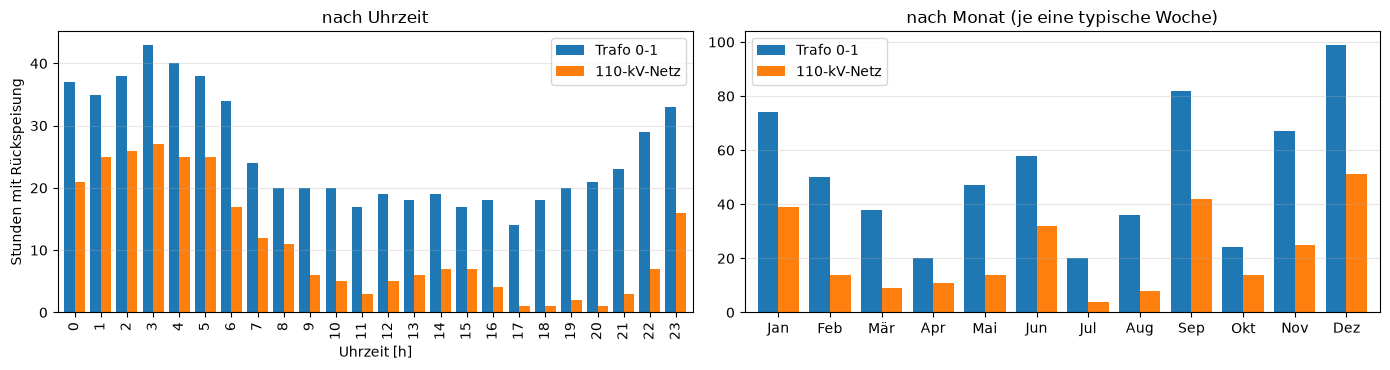

In [ ]:
info = r.info
rueck = pd.DataFrame({"Trafo 0-1": P0["Trafo 0-1"] < -SCHWELLE, "110-kV-Netz": P0["110-kV-Netz"] < -SCHWELLE})
monate = list(dict.fromkeys(info["month"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rueck.groupby(rueck.index.hour).sum().plot.bar(ax=axes[0], width=0.8)
axes[0].set_xlabel("Uhrzeit [h]")
axes[0].set_ylabel("Stunden mit Rückspeisung")
axes[0].set_title("nach Uhrzeit")
rueck.groupby(info["month"].to_numpy()).sum().reindex(monate).plot.bar(ax=axes[1], width=0.8)
axes[1].set_xticklabels([Month[m].label[:3] for m in monate], rotation=0)
axes[1].set_xlabel("")
axes[1].set_title("nach Monat (je eine typische Woche)")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Auslösende Bedingungen:** Trafo 0-1 kehrt sich um, wenn der Windpark mehr einspeist, als Abgang 1 (Bus 1 bis Bus 11) verbraucht. Die Netzkuppelstelle kehrt sich um, wenn Windpark und PV-Anlage zusammen mehr einspeisen, als das ganze Netz verbraucht. Die gestrichelte Linie markiert Erzeugung = Last; jeder Punkt ist eine Stunde.

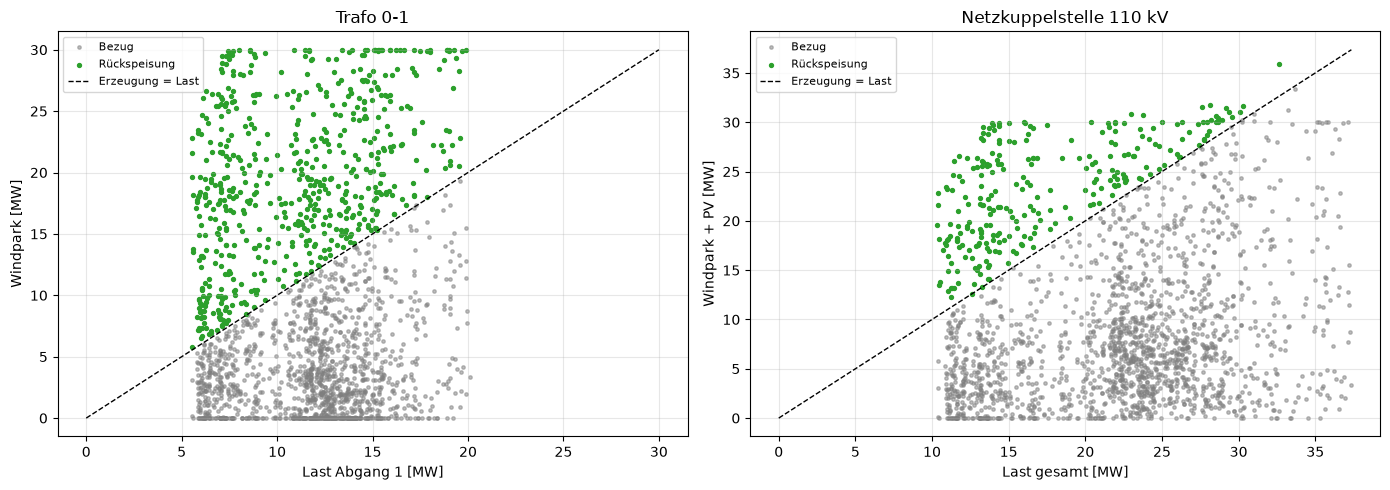

,Stunden,Wind im Mittel [MW],PV im Mittel [MW],Last gesamt im Mittel [MW],Anteil nachts (22–6 Uhr),Anteil Wochenende
Rückspeisung Trafo 0-1,615.00,19.41,0.71,20.56,0.48,0.31
Rückspeisung 110 kV,263.00,22.74,0.59,17.32,0.65,0.36
alle Stunden,2016.00,8.62,1.40,22.00,0.33,0.29


In [ ]:
bus_der_last = basis.net.load.set_index("name")["bus"].map(basis.net.bus["name"])
abgang1 = [l for l, b in bus_der_last.items() if b in [f"Bus {i}" for i in range(1, 12)]]
last_abgang1 = r.load_p_mw[abgang1].sum(axis=1)
last_gesamt = r.load_p_mw.sum(axis=1)
wind, pv = r.sgen_p_mw["Windpark"], r.sgen_p_mw["PV-Freifläche"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, y, umkehr, titel, xl, yl in (
        (axes[0], last_abgang1, wind, rueck["Trafo 0-1"], "Trafo 0-1", "Last Abgang 1 [MW]", "Windpark [MW]"),
        (axes[1], last_gesamt, wind + pv, rueck["110-kV-Netz"], "Netzkuppelstelle 110 kV", "Last gesamt [MW]", "Windpark + PV [MW]")):
    ax.scatter(x[~umkehr], y[~umkehr], s=6, color="tab:gray", alpha=0.5, label="Bezug")
    ax.scatter(x[umkehr], y[umkehr], s=8, color="tab:green", label="Rückspeisung")
    m = max(x.max(), y.max())
    ax.plot([0, m], [0, m], "k--", lw=1, label="Erzeugung = Last")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(titel)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

bedingungen = pd.DataFrame({
    titel: {"Stunden": int(u.sum()), "Wind im Mittel [MW]": wind[u].mean(), "PV im Mittel [MW]": pv[u].mean(),
            "Last gesamt im Mittel [MW]": last_gesamt[u].mean(), "Anteil nachts (22–6 Uhr)": (u & ((u.index.hour >= 22) | (u.index.hour < 6))).sum() / max(u.sum(), 1),
            "Anteil Wochenende": (u & (u.index.dayofweek >= 5)).sum() / max(u.sum(), 1)}
    for titel, u in (("Rückspeisung Trafo 0-1", rueck["Trafo 0-1"]), ("Rückspeisung 110 kV", rueck["110-kV-Netz"]),
                     ("alle Stunden", pd.Series(True, index=rueck.index)))})
plots.table(bedingungen.T, decimals=2)

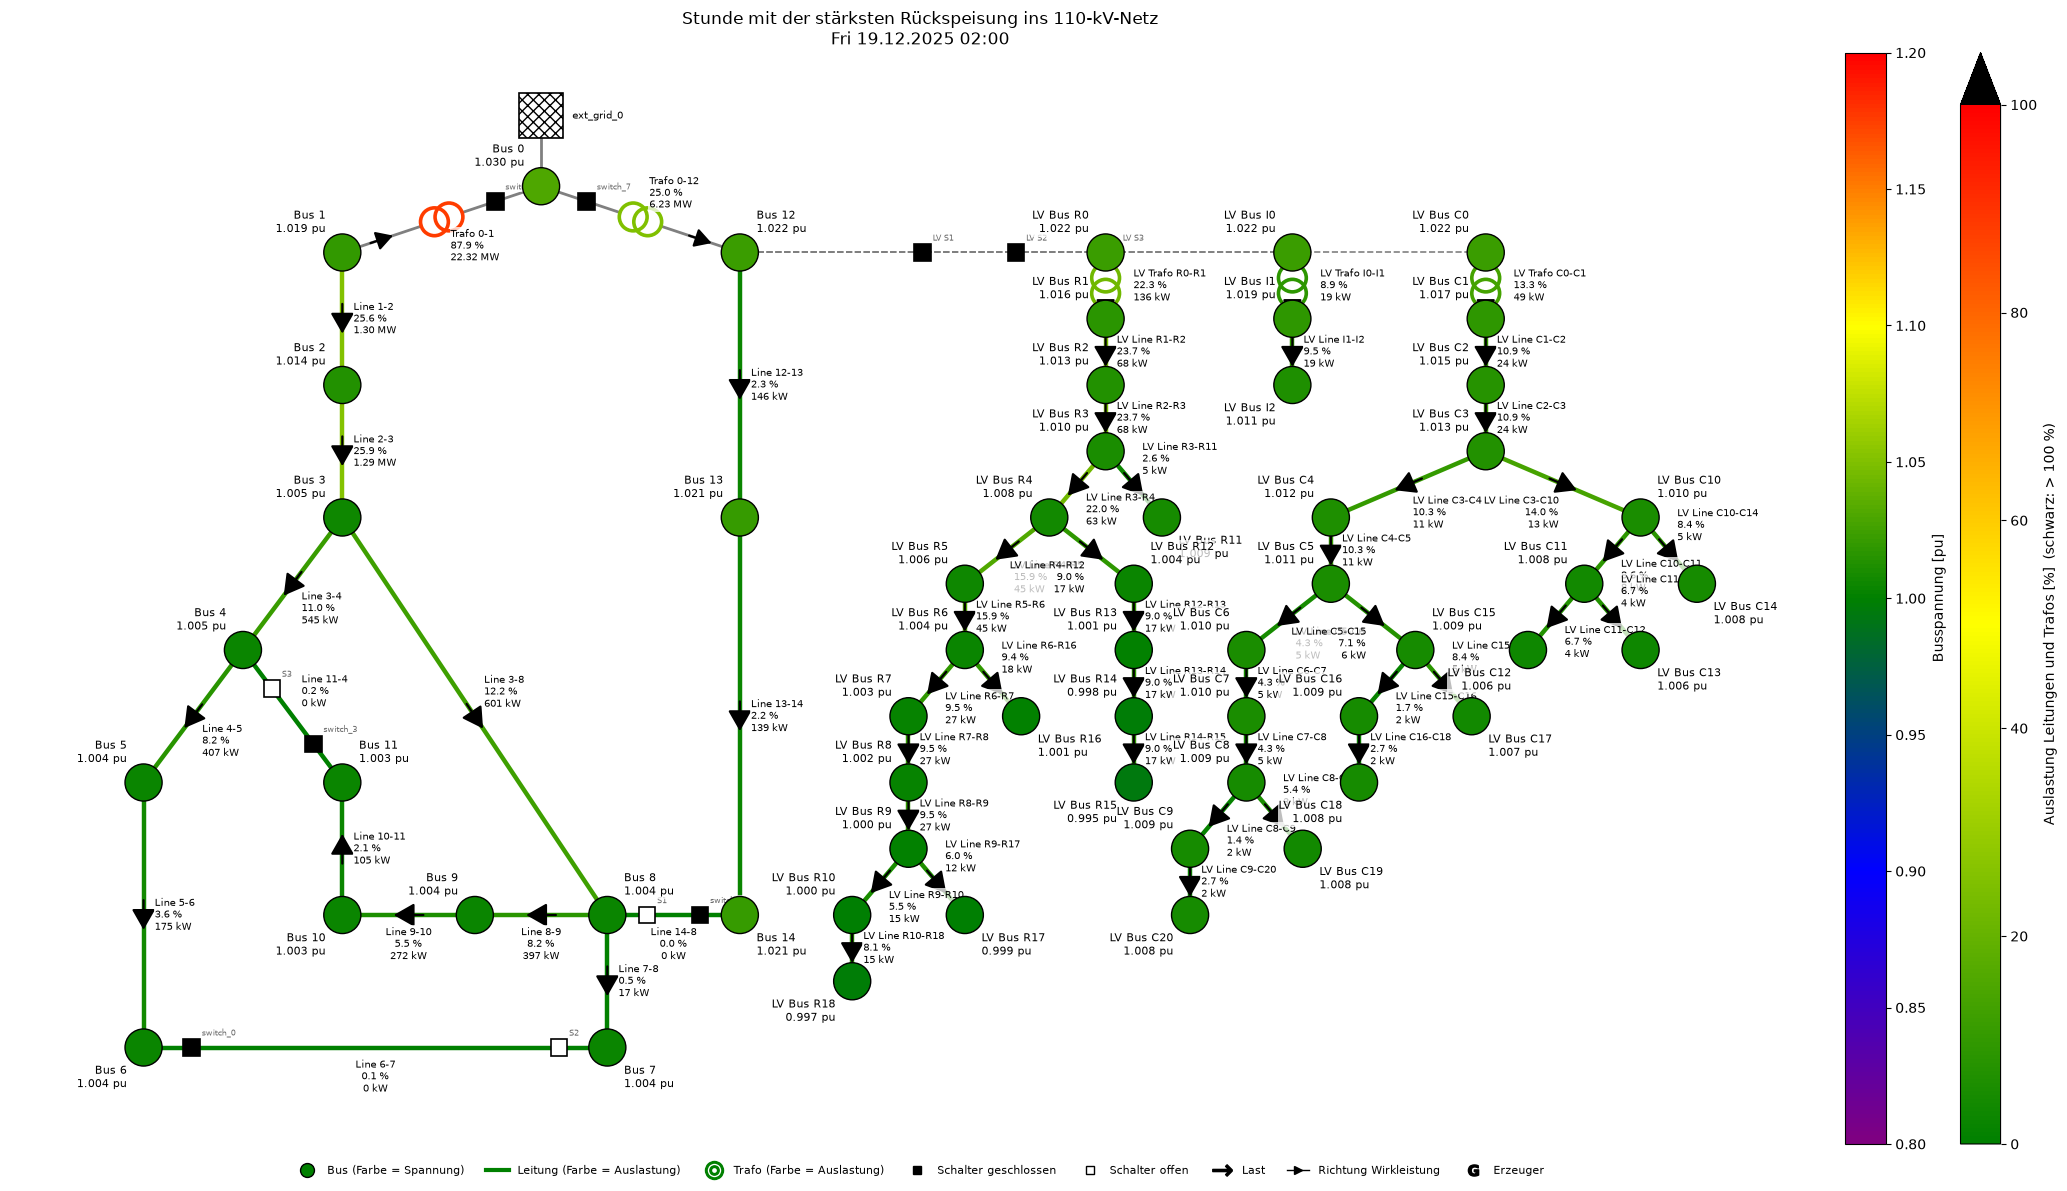

In [ ]:
normal.createDiagram(Diagram.NETWORK, time=[h_rueck], elements=False, title="Stunde mit der stärksten Rückspeisung ins 110-kV-Netz")

**Ergebnis Normalzustand:**

- **Wo:** Der Leistungsfluss kehrt sich nur an zwei Stellen um: an **Trafo 0-1** (615 von 2016 Stunden, bis 22,5 MW) und an der **Netzkuppelstelle zum 110-kV-Netz** (263 Stunden, bis 16,1 MW). Alle MS-Leitungen, Trafo 0-12 und das ganze Ortsnetz behalten immer ihre Richtung.
- **Warum nur dort:** Windpark und PV-Anlage speisen direkt an den Trafo-Sammelschienen ein. Ein Überschuss fließt sofort über den Trafo ab und läuft nie durch die Abgänge. Die PV-Haushalte (P25, S25) sind reine Bezugsprofile ohne Einspeisung und verringern nur den Bezug.
- **Auslöser:** Die Umkehr wird praktisch nur durch **Wind** ausgelöst. In den Stunden mit Rückspeisung speist der Windpark im Mittel 19 MW (Trafo 0-1) bzw. 23 MW (110 kV) ein, sonst im Mittel knapp 9 MW. Die PV-Anlage liegt in diesen Stunden sogar unter ihrem Mittelwert (0,6 bis 0,7 MW gegenüber 1,4 MW). Die Regel lässt sich direkt im Streudiagramm ablesen:
  - Trafo 0-1 speist zurück, sobald der Windpark mehr einspeist, als Abgang 1 verbraucht.
  - Das 110-kV-Netz bekommt Leistung zurück, sobald Wind und PV zusammen mehr liefern, als das ganze Netz verbraucht.
- **Wann:** Rückspeisung ins 110-kV-Netz tritt vor allem **nachts** auf (65 % der Stunden zwischen 22 und 6 Uhr), wenn die Last niedrig ist, und häufiger am Wochenende. Nach Monaten ist sie in den windreichen Wochen am häufigsten (Dezember, September, Januar) und im Juli und April am seltensten. Weil je Monat nur eine typische Woche gerechnet wird, spiegelt das eher das Wetter dieser einzelnen Woche als eine Jahreszeit; tendenziell liegt der Schwerpunkt im Winterhalbjahr. Abends kommt sie kaum vor, weil dann die Haushaltslast am höchsten ist.
- **PV allein reicht nie:** 10 MWp an Bus 12 liegen mittags immer unter der Last von Abgang 2 und des Netzes, deshalb kehrt sich Trafo 0-12 nie um.

## 4 Alle Schalterstellungen: Änderung der Leistungsflüsse

Die acht Schaltzustände (S1, S2, S3 jeweils offen oder geschlossen) werden als feste Betriebszustände über 12 Wochen gerechnet, wie in Teil 1 und Teil 3b.

In [ ]:
alle = sz.zeitreihe_alle(basis, prefix="w4_t5", controllers=lv_regler(basis.net))
P = {k: fluesse(s) for k, s in alle.items()}
spalten = {k: sz.label(k, kurz=True) for k in alle}
elemente = [c for c in P["000"] if c.startswith(("Line", "Trafo", "LV Trafo")) or c == "110-kV-Netz"]
print(len(alle), "Schaltzustände;", len(elemente), "Elemente (MS-Leitungen, alle Trafos, Netzkuppelstelle)")

Simulation 'w4_t5_000': unverändert seit dem Lauf vom 2026-11-07T16:41:33 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_001': unverändert seit dem Lauf vom 2026-11-07T16:42:55 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_010': unverändert seit dem Lauf vom 2026-11-07T16:44:05 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_011': unverändert seit dem Lauf vom 2026-11-07T16:45:15 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_100': unverändert seit dem Lauf vom 2026-11-07T16:46:25 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_101': unverändert seit dem Lauf vom 2026-11-07T16:47:35 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_110': unverändert seit dem Lauf vom 2026-11-07T16:48:45 – gespeicherte Ergebnisse gelade

**Mittlere Änderung des Wirkleistungsflusses gegenüber dem Normalzustand (alle Schalter offen)** in MW, gemittelt über alle 2016 Stunden. Das Vorzeichen bezieht sich auf die Richtung des Ergebnisfelds (Abschnitt 2): Ein positiver Wert heißt, der Fluss in Richtung `from_bus` → `to_bus` bzw. OS → US nimmt zu. Die Leitungen mit S1–S3 (Line 14-8, 6-7, 11-4) führen im Normalzustand keine Leistung; bei ihnen ist die Änderung der Fluss selbst.

In [ ]:
delta_mittel = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).mean() for k in alle if k != "000"})
plots.table(delta_mittel, decimals=3, cmap="RdBu_r", vmin=-1.5, vmax=1.5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.001,-0.000,-0.001,-0.290,-0.270,-0.294,-0.276
Line 2-3,-0.001,-0.000,-0.001,-0.288,-0.269,-0.291,-0.274
Line 3-4,0.365,0.010,0.301,-0.000,0.275,-0.054,0.191
Line 4-5,0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 5-6,0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 7-8,-0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 8-9,-0.365,-0.000,-0.430,-0.000,-0.275,-0.000,-0.355
Line 9-10,-0.365,-0.000,-0.429,-0.000,-0.275,-0.000,-0.355
Line 10-11,-0.365,-0.000,-0.429,-0.000,-0.275,-0.000,-0.355
Line 3-8,-0.366,-0.010,-0.302,-0.284,-0.540,-0.234,-0.462


**Größte Änderung in einer einzelnen Stunde** (Betrag, MW):

In [ ]:
delta_max = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).abs().max() for k in alle if k != "000"})
plots.table(delta_max, decimals=3, cmap="Reds", vmin=0, vmax=5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,0.002,0.000,0.003,2.301,2.373,2.337,2.381
Line 2-3,0.002,0.000,0.003,2.254,2.324,2.292,2.331
Line 3-4,0.597,0.119,0.519,0.000,1.118,0.560,1.192
Line 4-5,0.000,0.119,0.309,0.000,0.000,0.559,0.561
Line 5-6,0.000,0.119,0.308,0.000,0.000,0.558,0.560
Line 7-8,0.000,0.118,0.307,0.000,0.000,0.558,0.560
Line 8-9,0.595,0.000,0.717,0.000,1.113,0.000,1.047
Line 9-10,0.595,0.000,0.716,0.000,1.113,0.000,1.047
Line 10-11,0.594,0.000,0.715,0.000,1.114,0.000,1.047
Line 3-8,0.599,0.119,0.521,2.200,1.951,1.729,1.683


**Stunden mit anderer Flussrichtung als im Normalzustand** (beide Werte |P| ≥ 1 kW, Vorzeichen verschieden). Die drei Leitungen mit S1–S3 fehlen hier, weil sie im Normalzustand keine Leistung führen:

In [ ]:
def richtungswechsel(Pk, P0):
    beide = (Pk.abs() >= SCHWELLE) & (P0.abs() >= SCHWELLE)
    return (beide & (np.sign(Pk) != np.sign(P0))).sum()

fuehrend = [c for c in elemente if (P["000"][c].abs() >= SCHWELLE).any()]
wechsel = pd.DataFrame({spalten[k]: richtungswechsel(P[k][fuehrend], P["000"][fuehrend]) for k in alle if k != "000"})
plots.table(wechsel.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=2016)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,0,0,0,0,0,0,0
Line 2-3,0,0,0,0,0,0,0
Line 3-4,0,0,0,0,0,0,0
Line 4-5,0,0,0,0,0,0,0
Line 5-6,0,0,0,0,0,112,218
Line 7-8,0,498,0,0,0,581,213
Line 8-9,0,0,0,0,286,0,299
Line 9-10,465,0,640,0,549,0,638
Line 10-11,2016,0,2016,0,1101,0,1527
Line 3-8,0,0,0,364,428,137,193


**Stunden in Gegenrichtung je Schaltzustand** (bezogen auf die Hauptrichtung im jeweiligen Zustand, wie in Abschnitt 3), dazu die Rückspeisung ins 110-kV-Netz:

In [ ]:
gegen = pd.DataFrame({spalten[k]: richtungen(P[k][elemente])["Stunden Gegenrichtung"] for k in alle})
gegen = gegen.loc[(gegen > 0).any(axis=1)]
display(plots.table(gegen.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=1008))
rueck_alle = pd.DataFrame({spalten[k]: {"Stunden Rückspeisung 110 kV": int((P[k]["110-kV-Netz"] < -SCHWELLE).sum()),
                                         "max. Rückspeisung 110 kV [MW]": float(-P[k]["110-kV-Netz"].min()),
                                         "Stunden Rückspeisung Trafo 0-1": int((P[k]["Trafo 0-1"] < -SCHWELLE).sum()),
                                         "Stunden Rückspeisung Trafo 0-12": int((P[k]["Trafo 0-12"] < -SCHWELLE).sum())}
                           for k in alle})
plots.table(rueck_alle.astype(float), decimals=2)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 5-6,0,0,0,0,0,0,112,218
Line 7-8,0,0,498,0,0,0,581,213
Line 8-9,0,0,0,0,0,286,0,299
Line 9-10,0,465,0,640,0,549,0,638
Line 10-11,0,0,0,0,0,911,0,481
Line 3-8,0,0,0,0,364,428,137,193
Line 12-13,0,0,0,0,515,538,519,534
Line 13-14,0,0,0,0,526,546,531,542
Line 6-7,0,0,776,0,0,0,661,268
Line 11-4,0,0,0,0,0,265,0,15


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden Rückspeisung 110 kV,263.00,263.00,263.00,263.00,261.00,261.00,261.00,261.00
max. Rückspeisung 110 kV [MW],16.09,16.09,16.09,16.09,15.86,15.86,15.86,15.86
Stunden Rückspeisung Trafo 0-1,615.00,615.00,615.00,615.00,613.00,612.00,613.00,612.00
Stunden Rückspeisung Trafo 0-12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


**Ergebnis aller Schalterstellungen:**

- **Ortsnetz:** In keinem Schaltzustand ändert sich der Fluss an den Ortsnetztrafos (Änderung 0,000 MW). Die Schalter wirken nur im MS-Netz.
- **S2 und S3 (Maschen in Abgang 1):** Sie verteilen nur die Last innerhalb von Abgang 1 um (im Mittel 0,1 bis 0,4 MW je Leitung). Auf den Trafos und an der Netzkuppelstelle bleibt alles gleich. Die Leitungen am Ende der Stränge erhalten dabei eine neue Richtung:
  - Mit geschlossenem S3 wird Bus 11 über Line 11-4 versorgt, und Line 10-11 läuft in allen 2016 Stunden andersherum (von Bus 11 zu Bus 10).
  - Line 9-10 dreht in 465 Stunden.
  - Mit S2 dreht Line 7-8 in 498 Stunden.
- **S1 (Kupplung der Abgänge) erzeugt Lastflussumkehr auf MS-Leitungen.** Über S1 wird im Mittel etwa 0,3 MW von Trafo 0-1 auf Trafo 0-12 verlagert, in einzelnen Stunden bis 2,3 MW. Die Richtung auf der Kupplung Line 14-8 hängt vom Wind ab:
  - **wenig Wind:** Abgang 2 stützt Abgang 1, die Leistung fließt von Bus 14 zu Bus 8.
  - **viel Wind** (in rund 665 Stunden, im Mittel 18,5 MW Wind): Der Windpark drückt Leistung über Abgang 1 und S1 in Abgang 2. Line 14-8, Line 13-14 und Line 12-13 kehren sich dann um (515 bis 546 Stunden). In fast allen dieser Stunden speist auch Trafo 0-1 zurück.
  - **mittags mit PV und wenig Wind:** Ein zweites Muster betrifft Line 3-8 (364 Stunden, im Mittel 3,9 MW PV und unter 1 MW Wind). Ohne Wind muss Trafo 0-1 ganz Abgang 1 versorgen, während Abgang 2 durch die PV-Anlage entlastet ist. Über S1 übernimmt Abgang 2 dann Bus 8 bis 11 und zusätzlich einen Teil von Bus 3: Line 3-8 läuft von Bus 8 zu Bus 3.
- **Netzkuppelstelle:** Mit S1 sinken die Rückspeisestunden leicht (263 → 261), weil Abgang 2 einen Teil des Windstroms abnimmt. Die Verluste steigen.
- **Erste Folge für die Auslastung:** Mit geschlossenem S1 steigt die höchste MS-Leitungsauslastung auf 98 bis 99,6 % (Line 1-2, 6. Januar, 18 Uhr, 30 MW Wind). Ein Teil des Windstroms läuft über Line 1-2 und S1 in Abgang 2. In der Untersuchung der Folgen ist das genauer anzusehen.

## 5 Folgen für Spannungen und Auslastungen

Alle Werte als **Differenz gegenüber dem Normalzustand** (alle Schalter offen), jeweils für die niedrigste, die mittlere und die höchste Spannung bzw. Auslastung über 12 Wochen. Spannungen in Prozentpunkten (0,01 pu = 1 Prozentpunkt), Auslastungen in Prozentpunkten der Bemessungsgröße.

Zuerst die wichtigsten Kennwerte je Schaltzustand als absolute Werte:

In [ ]:
k_werte, _ = bw.kennwerte({spalten[k]: s for k, s in alle.items()})
plots.table(k_werte[["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Stunden U < 0,95 MS", "Leitung max MS [%]",
                     "Leitung max NS [%]", "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Verluste [MWh]"]].astype(float).T, decimals=3)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
U min MS [pu],0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
U max MS [pu],1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
U min NS [pu],0.950,0.950,0.950,0.950,0.950,0.950,0.950,0.950
U max NS [pu],1.026,1.026,1.026,1.026,1.038,1.038,1.038,1.038
"Stunden U < 0,95 MS",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Leitung max MS [%],78.491,78.436,78.489,78.416,98.086,99.604,98.517,99.576
Leitung max NS [%],69.969,69.969,69.969,69.969,70.170,70.169,70.173,70.171
Trafo max HS/MS [%],88.512,88.513,88.512,88.513,78.536,78.242,78.388,78.208
Ortsnetztrafo max [%],65.830,65.830,65.830,65.830,66.009,66.008,66.012,66.010
Verluste [MWh],150.712,148.959,150.651,148.668,183.453,184.868,183.997,184.385


### 5.1 Spannungen an allen Bussen

Alle MS-Busse und alle NS-Busse des Ortsnetzes:

In [ ]:
g = lvnetz.bus_groups(basis.net)
MS_BUSSE = [f"Bus {i}" for i in range(1, 15)]
ALLE_BUSSE = MS_BUSSE + list(g["NS"])
U = {k: s.results.vm_pu[ALLE_BUSSE] for k, s in alle.items()}

def differenz(werte, statistik, faktor=1.0):
    """Differenz der Statistik (min/mean/max über die Zeit) gegenüber dem Normalzustand, mal faktor."""
    ref = getattr(werte["000"], statistik)()
    return pd.DataFrame({spalten[k]: (getattr(werte[k], statistik)() - ref) * faktor for k in alle if k != "000"})

for stat, titel in (("min", "niedrigste Spannung"), ("mean", "mittlere Spannung"), ("max", "höchste Spannung")):
    print(f"Änderung der {titel} gegenüber dem Normalzustand [Prozentpunkte]")
    display(plots.table(differenz(U, stat, 100), decimals=2, cmap="RdBu", vmin=-3, vmax=3))

Änderung der niedrigste Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.26,0.25,0.26,0.26
Bus 2,0.00,0.00,0.01,1.02,1.01,1.03,1.02
Bus 3,0.01,0.00,0.01,2.18,2.16,2.21,2.19
Bus 4,-0.06,-0.00,-0.04,2.18,2.15,2.25,2.20
Bus 5,-0.06,-0.00,-0.02,2.19,2.15,2.28,2.24
Bus 6,-0.06,-0.00,0.04,2.19,2.16,2.36,2.35
Bus 7,0.15,0.00,0.06,2.50,2.52,2.38,2.37
Bus 8,0.15,0.00,0.13,2.50,2.52,2.47,2.49
Bus 9,0.19,0.00,0.17,2.50,2.53,2.47,2.52
Bus 10,0.27,0.00,0.27,2.51,2.55,2.47,2.57


Änderung der mittlere Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.28,0.28,0.28,0.28
Bus 2,0.00,0.00,0.00,0.65,0.65,0.66,0.66
Bus 3,0.00,0.00,0.00,1.25,1.24,1.26,1.25
Bus 4,-0.04,-0.00,-0.03,1.25,1.23,1.28,1.25
Bus 5,-0.04,-0.01,-0.02,1.25,1.23,1.29,1.27
Bus 6,-0.04,-0.01,0.01,1.25,1.23,1.33,1.33
Bus 7,0.09,0.02,0.05,1.42,1.44,1.37,1.37
Bus 8,0.09,0.01,0.08,1.42,1.44,1.41,1.43
Bus 9,0.11,0.01,0.10,1.42,1.45,1.41,1.44
Bus 10,0.16,0.01,0.16,1.42,1.47,1.41,1.47


Änderung der höchste Spannung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Bus 1,0.00,0.00,0.00,0.49,0.51,0.50,0.51
Bus 2,0.00,0.00,0.00,0.58,0.59,0.59,0.60
Bus 3,0.00,0.00,0.00,0.78,0.79,0.79,0.80
Bus 4,-0.02,-0.00,-0.01,0.78,0.78,0.80,0.80
Bus 5,-0.02,-0.00,-0.01,0.78,0.78,0.81,0.81
Bus 6,-0.02,-0.00,0.01,0.78,0.78,0.82,0.83
Bus 7,0.04,0.00,0.01,0.85,0.87,0.83,0.84
Bus 8,0.04,0.00,0.03,0.85,0.87,0.85,0.87
Bus 9,0.04,0.00,0.04,0.85,0.87,0.85,0.87
Bus 10,0.07,0.00,0.06,0.85,0.88,0.85,0.89


**Ergebnis Spannungen:**

- **S2 und S3** ändern die Spannungen um höchstens 0,3 Prozentpunkte:
  - S3 hebt Bus 7 bis 11 leicht an (an Bus 11 bis +0,31 Prozentpunkte bei der niedrigsten Spannung) und senkt Bus 4 bis 6 minimal.
  - S2 wirkt praktisch nicht.
  - Abgang 2 und das Ortsnetz bleiben unverändert.
- **S1** verschiebt die Spannung zwischen den Abgängen:
  - **Abgang 1 steigt:** Die niedrigste Spannung an Bus 3 bis 11 steigt um 2,2 bis 2,6 Prozentpunkte, die mittlere um 1,2 bis 1,5. Die niedrigste MS-Spannung im ganzen Netz steigt von 0,951 auf 0,974 bis 0,976 pu.
  - **Abgang 2 sinkt:** Bus 12 fällt bei der niedrigsten Spannung um 1,0 Prozentpunkte, Bus 14 um 1,9. Abgang 2 versorgt über S1 einen Teil von Abgang 1 mit.
  - **Höchstwert:** Die höchste MS-Spannung steigt leicht (1,025 → 1,030 pu), weil der Windpark bei Rückspeisung über S1 auch Abgang 2 anhebt.
- **Ortsnetz:** Die Sammelschienen folgen Bus 12 und liegen mit S1 bis 0,7 Prozentpunkte tiefer. An den Strangenden (den jeweils schwächsten Bussen) ändert sich die niedrigste Spannung trotzdem kaum, weil die rONT den Unterschied ausgleichen (Abschnitt 6). An den Bussen nahe der Sammelschiene ist die Absenkung dagegen in der Tabelle sichtbar. Dafür steigt die höchste NS-Spannung im Wohngebiet um 1,2 Prozentpunkte (auf 1,038 pu). Das passiert in den Stunden, in denen der rONT zwei Stufen hochschaltet und die Sammelschiene dadurch über die Strangenden hinaus anhebt. Das Planungsband wird nicht verletzt.

### 5.2 Auslastung aller Leitungen und Trafos

Alle MS- und NS-Leitungen und alle Trafos:

In [ ]:
ALLE_LEITUNGEN = list(normal.results.line_loading.columns)
TRAFOS = list(normal.results.trafo_loading.columns)
A = {k: pd.concat([s.results.line_loading[ALLE_LEITUNGEN], s.results.trafo_loading[TRAFOS]], axis=1) for k, s in alle.items()}
for stat, titel in (("mean", "mittlere Auslastung"), ("max", "höchste Auslastung")):
    print(f"Änderung der {titel} gegenüber dem Normalzustand [Prozentpunkte]")
    display(plots.table(differenz(A, stat), decimals=1, cmap="RdBu_r", vmin=-20, vmax=20))

Änderung der mittlere Auslastung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.0,-0.0,-0.0,-5.3,-4.8,-5.3,-4.9
Line 2-3,-0.0,-0.0,-0.0,-5.4,-5.0,-5.5,-5.1
Line 3-4,7.7,0.3,6.4,-0.3,5.5,-1.3,3.9
Line 4-5,0.0,0.3,-2.6,-0.2,-0.2,-1.1,-3.5
Line 5-6,0.0,0.3,-2.6,-0.1,-0.1,-0.4,-2.8
Line 7-8,-0.0,0.2,2.5,-0.0,-0.0,4.3,4.4
Line 8-9,-7.7,-0.0,-9.0,-0.2,-2.1,-0.2,-4.4
Line 9-10,-7.0,-0.0,-7.8,-0.1,-0.9,-0.1,-3.0
Line 10-11,1.0,-0.0,2.2,-0.1,2.6,-0.1,2.0
Line 3-8,-7.8,-0.3,-6.5,-1.8,-8.4,-3.0,-7.9


Änderung der höchste Auslastung gegenüber dem Normalzustand [Prozentpunkte]


,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.1,-0.0,-0.1,20.0,21.5,20.4,21.5
Line 2-3,-0.1,-0.0,-0.1,19.4,20.9,19.8,20.9
Line 3-4,11.9,-1.7,8.6,-0.9,15.3,-0.1,14.5
Line 4-5,0.0,-1.7,-6.6,-0.6,-0.6,1.0,-5.5
Line 5-6,0.0,-1.4,-6.4,-0.3,-0.3,4.7,-2.2
Line 7-8,-0.0,0.3,5.2,-0.0,-0.0,10.9,9.9
Line 8-9,-12.7,-0.0,-13.5,-0.6,-1.4,-0.6,-4.8
Line 9-10,-12.0,0.0,-14.6,-0.5,2.3,-0.5,-1.5
Line 10-11,1.8,0.0,2.6,-0.2,14.7,-0.2,12.3
Line 3-8,-13.0,0.3,-10.3,31.8,9.2,20.9,6.8


**Höchste Auslastung je Schaltzustand** (absolute Werte in %):

In [ ]:
plots.table(pd.DataFrame({spalten[k]: A[k].max() for k in alle}), decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,78.1,78.0,78.1,78.0,98.1,99.6,98.5,99.6
Line 2-3,78.5,78.4,78.5,78.4,97.9,99.4,98.3,99.4
Line 3-4,36.5,48.4,34.8,45.1,35.6,51.8,36.4,50.9
Line 4-5,27.3,27.3,25.6,20.7,26.6,26.6,28.3,21.8
Line 5-6,11.8,11.8,10.4,5.3,11.5,11.5,16.5,9.6
Line 7-8,1.8,1.8,2.2,7.1,1.8,1.8,12.7,11.8
Line 8-9,24.6,11.8,24.6,11.0,23.9,23.2,24.0,19.8
Line 9-10,17.7,5.8,17.8,3.1,17.3,20.1,17.3,16.3
Line 10-11,7.1,8.8,7.1,9.6,6.9,21.8,6.9,19.4
Line 3-8,36.3,23.2,36.5,26.0,68.1,45.4,57.1,43.0


**Ergebnis Auslastungen:**

- **S3** verteilt die Last in Abgang 1 um: Line 8-9 und 9-10 werden um 12 bis 15 Prozentpunkte entlastet (höchste Auslastung), Line 3-4 und die Masche Line 11-4 übernehmen entsprechend mehr. **S2** ändert nur wenig (höchstens 3 Prozentpunkte). Beide senken die Verluste leicht (bis −1,4 %).
- **S1** ist der einzige Zustand mit großen Änderungen:
  - **110/20-kV-Trafos:** Die höchste Auslastung von Trafo 0-1 sinkt um 10 Prozentpunkte (88,5 → 78,5 %), Trafo 0-12 steigt um 5,7 Prozentpunkte. Die beiden Trafos teilen sich die Last gleichmäßiger.
  - **Kupplung und Abgang 2:** Line 14-8 trägt jetzt bis zu 44 %. Line 12-13 und 13-14 steigen um rund 35 Prozentpunkte (von 8 auf über 40 %) und im Mittel um 15 Prozentpunkte, weil über sie Leistung in beide Richtungen fließt (Abschnitt 4).
  - **Line 1-2 und 2-3:** Im Mittel werden sie entlastet (−5 Prozentpunkte), in einzelnen Stunden aber deutlich stärker belastet (+20 Prozentpunkte, bis 99,6 %). Das passiert bei viel Wind: Der Windstrom läuft dann über Line 1-2 durch Abgang 1 und über S1 in Abgang 2. Damit wird Line 1-2 mit S1 bei Starkwind zum Engpass.
  - **Line 3-8:** Mit S1 allein steigt sie um 32 Prozentpunkte (36 → 68 %). Schließt man zusätzlich S3, sind es nur 9 Prozentpunkte, weil sich die Leistung auf die Masche verteilt.
  - **Verluste:** Sie steigen mit S1 um 22 % (150,7 → 183 bis 185 MWh), weil Leistung über längere Wege fließt.
- **Ortsnetz:** Die Auslastung der Ortsnetztrafos und NS-Leitungen ändert sich in keinem Zustand um mehr als 0,6 Prozentpunkte.

## 6 Folgen für die rONT-Regelung

### 6.1 Stufenstellungen je Schaltzustand

Stunden, in denen jeder Ortsnetztrafo in der jeweiligen Stufe steht (`tap_pos`; −1 bzw. −2 heben die NS-Spannung um eine bzw. zwei Stufen an, +1 bzw. +2 senken sie), und die Zahl der Stufenschritte in 12 Wochen:

In [ ]:
ONT = {"R": "LV Trafo R0-R1", "I": "LV Trafo I0-I1", "C": "LV Trafo C0-C1"}
TAP = {k: s.results.tap_pos[list(ONT.values())] for k, s in alle.items()}

zeilen = {}
for k in alle:
    for x, t in ONT.items():
        for stufe in range(-2, 3):
            zeilen.setdefault((t, f"Stufe {stufe:+d}" if stufe else "Stufe 0"), {})[spalten[k]] = int((TAP[k][t] == stufe).sum())
        zeilen.setdefault((t, "Stufenschritte"), {})[spalten[k]] = int(TAP[k][t].diff().abs().sum())
stufen_tab = pd.DataFrame(zeilen).T
stufen_tab = stufen_tab.loc[(stufen_tab > 0).any(axis=1)]
plots.table(stufen_tab.astype(float), decimals=0)

### 6.2 Beispieltag

Der Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten vom Normalzustand unterscheiden. Je Ortsnetztrafo eine Zeile pro Schaltzustand; die Farbe zeigt die Stufe, die Zahl im Feld ebenfalls (leer = Neutralstellung).

Beispieltag: Montag, 06.01. (Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten unterscheiden)


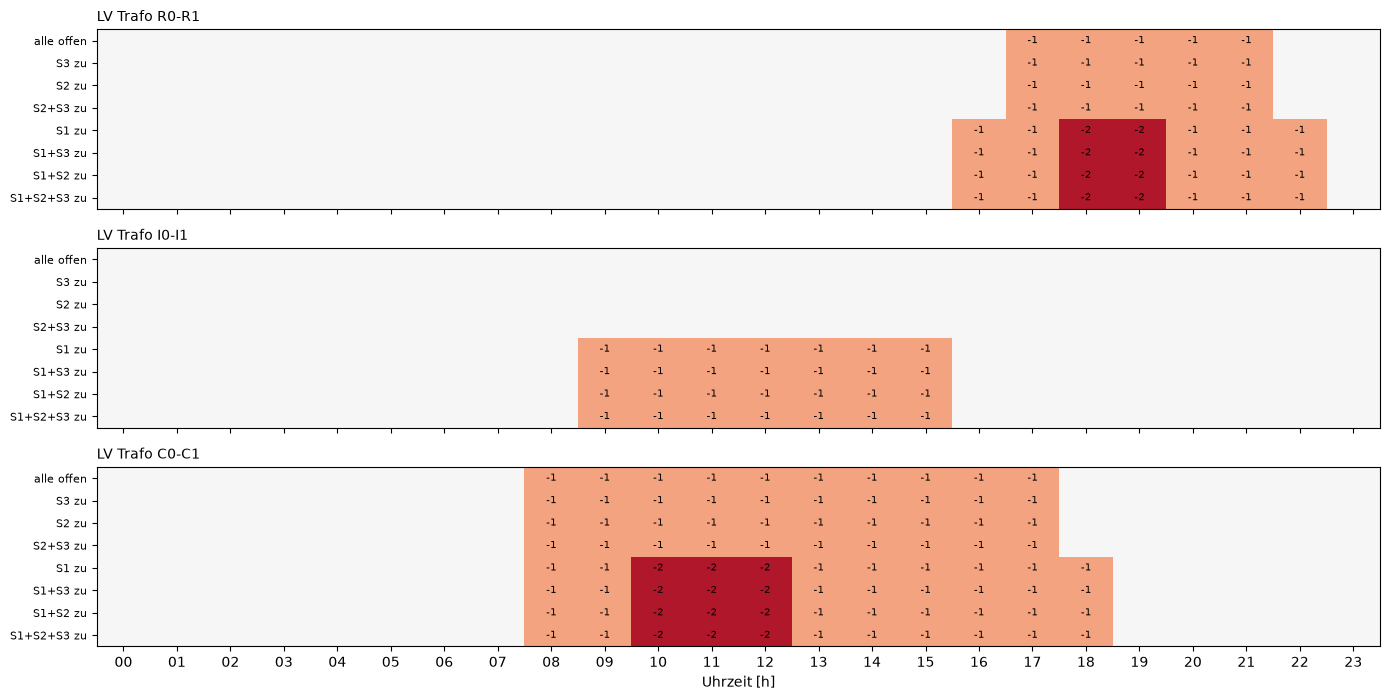

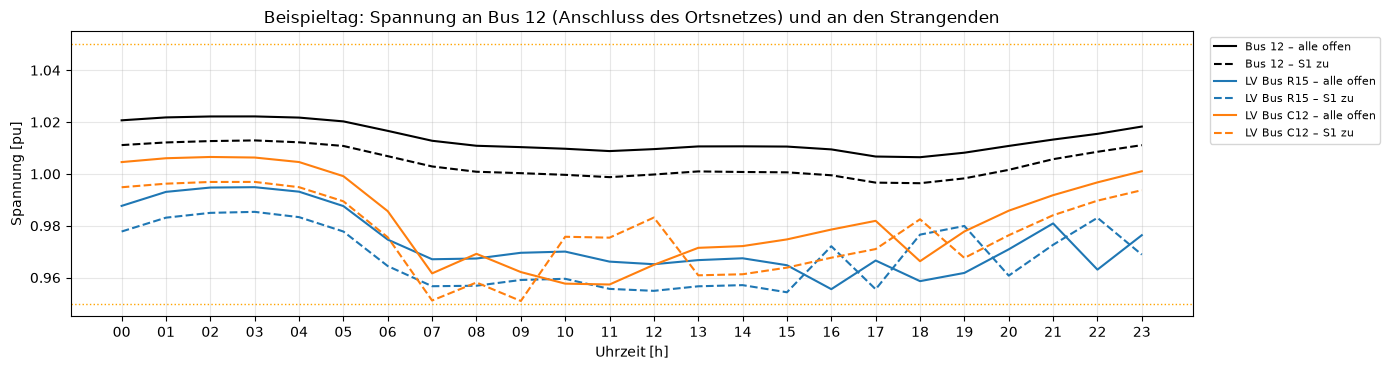

In [ ]:
unterschied = sum((TAP[k] - TAP["000"]).abs().sum(axis=1) for k in alle)          # Abweichung aller Zustände vom Normalzustand
tag = unterschied.groupby(unterschied.index.date).sum().idxmax()
stunden = TAP["000"].index[TAP["000"].index.date == tag]
TAGE = ["Montag", "Dienstag", "Mittwoch", "Donnerstag", "Freitag", "Samstag", "Sonntag"]
print(f"Beispieltag: {TAGE[pd.Timestamp(tag).weekday()]}, {pd.Timestamp(tag):%d.%m.} "
      f"(Tag, an dem sich die Stufenstellungen der Schaltzustände am stärksten unterscheiden)")

fig, axes = plt.subplots(len(ONT), 1, figsize=(14, 2.1 * len(ONT) + 0.8), sharex=True)
for ax, (x, t) in zip(axes, ONT.items()):
    daten = pd.DataFrame({spalten[k]: TAP[k].loc[stunden, t].to_numpy() for k in alle}).T
    ax.imshow(daten, aspect="auto", cmap="RdBu", vmin=-2.5, vmax=2.5)
    for i in range(daten.shape[0]):
        for j in range(daten.shape[1]):
            if daten.iat[i, j] != 0:
                ax.text(j, i, f"{int(daten.iat[i, j]):+d}", ha="center", va="center", fontsize=7)
    ax.set_yticks(range(len(daten)), daten.index, fontsize=8)
    ax.set_title(t, fontsize=10, loc="left")
axes[-1].set_xticks(range(len(stunden)), [f"{h:%H}" for h in stunden])
axes[-1].set_xlabel("Uhrzeit [h]")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 3.8))
for bus, farbe in (("Bus 12", "black"), ("LV Bus R15", "tab:blue"), ("LV Bus C12", "tab:orange")):
    for k, ls in (("000", "-"), ("100", "--")):
        ax.plot(range(len(stunden)), alle[k].results.vm_pu.loc[stunden, bus], ls, color=farbe, label=f"{bus} – {spalten[k]}")
for v in (V_PLAN_MIN, V_PLAN_MAX):
    ax.axhline(v, color="orange", ls=":", lw=1)
ax.set_xticks(range(len(stunden)), [f"{h:%H}" for h in stunden])
ax.set_xlabel("Uhrzeit [h]")
ax.set_ylabel("Spannung [pu]")
ax.set_title("Beispieltag: Spannung an Bus 12 (Anschluss des Ortsnetzes) und an den Strangenden")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 Schalten die rONT in allen Schaltzuständen zur gleichen Zeit?

Für jeden Ortsnetztrafo und Schaltzustand wird mit dem Normalzustand verglichen:

- **Stunden mit anderer Stufe:** In wie vielen Stunden steht der Trafo in einer anderen Stufe als im Normalzustand?
- **Schaltzeitpunkte gleich:** Anteil der Stufenschritte, die in derselben Stunde auch im Normalzustand stattfinden (bzw. höchstens eine Stunde früher oder später).
- **zusätzliche Stufenschritte:** Stufenschritte ohne Gegenstück im Normalzustand innerhalb von ±1 h (der rONT schaltet, obwohl er im Normalzustand nicht schalten würde).
- **fehlende Stufenschritte:** Stufenschritte des Normalzustands ohne Gegenstück innerhalb von ±1 h.

In [ ]:
def schaltzeitpunkte(tap):
    return tap.index[tap.diff().fillna(0) != 0]

zeilen = {}
for x, t in ONT.items():
    ref = schaltzeitpunkte(TAP["000"][t])
    for k in alle:
        if k == "000":
            continue
        z = schaltzeitpunkte(TAP[k][t])
        abstand = np.array([np.abs((ref - h) / pd.Timedelta(hours=1)).min() for h in z]) if len(ref) else np.full(len(z), np.inf)
        rueck = np.array([np.abs((z - h) / pd.Timedelta(hours=1)).min() for h in ref]) if len(z) else np.full(len(ref), np.inf)
        zeilen[(t, spalten[k])] = {
            "Stufenschritte": int(TAP[k][t].diff().abs().sum()),
            "Stufenschritte Normalzustand": int(TAP["000"][t].diff().abs().sum()),
            "Stunden mit anderer Stufe": int((TAP[k][t] != TAP["000"][t]).sum()),
            "Schaltzeitpunkte gleich [%]": 100 * (abstand == 0).mean() if len(abstand) else np.nan,
            "Schaltzeitpunkte ±1 h [%]": 100 * (abstand <= 1).mean() if len(abstand) else np.nan,
            "zusätzliche Stufenschritte": int((abstand > 1).sum()),
            "fehlende Stufenschritte": int((rueck > 1).sum()),
        }
gleichzeitig = pd.DataFrame(zeilen).T
plots.table(gleichzeitig.astype(float), decimals=1)

**Zu welcher Uhrzeit schalten die rONT?** Stufenschritte nach Uhrzeit, Normalzustand und alle Zustände mit S1 zusammen (je Zustand gemittelt):

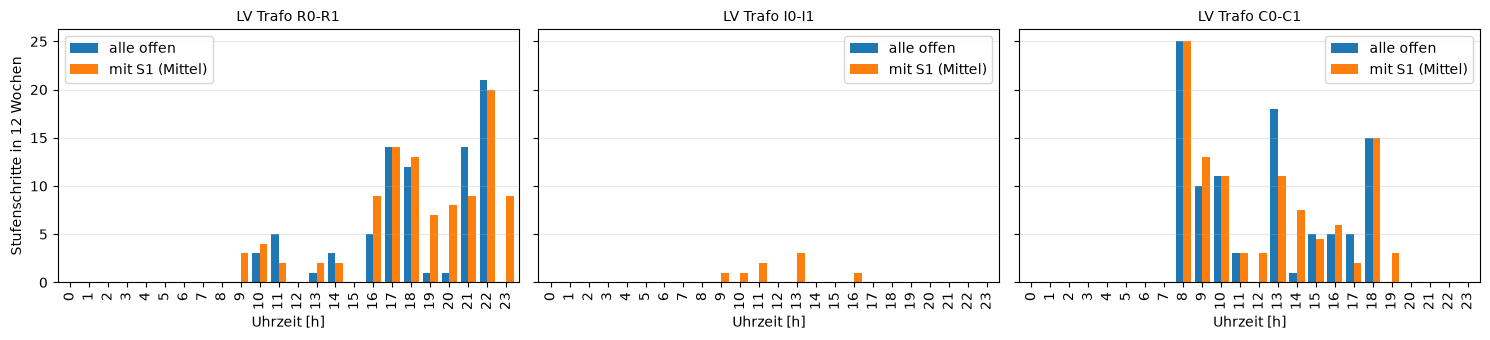

In [ ]:
fig, axes = plt.subplots(1, len(ONT), figsize=(15, 3.5), sharey=True)
mit_s1 = [k for k in alle if sz.zustand(k)["S1"]]
for ax, (x, t) in zip(axes, ONT.items()):
    n0 = TAP["000"][t].diff().abs().groupby(TAP["000"].index.hour).sum()
    n1 = sum(TAP[k][t].diff().abs().groupby(TAP[k].index.hour).sum() for k in mit_s1) / len(mit_s1)
    pd.DataFrame({"alle offen": n0, "mit S1 (Mittel)": n1}).plot.bar(ax=ax, width=0.8)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("Uhrzeit [h]")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Stufenschritte in 12 Wochen")
plt.tight_layout()
plt.show()

**Ergebnis rONT-Regelung:**

- **S2 und S3:** Die rONT schalten genau wie im Normalzustand, mit denselben Stufen zu denselben Zeitpunkten (100 %). Die Maschen in Abgang 1 wirken nicht bis ins Ortsnetz.
- **S1:** Alle drei rONT müssen mehr regeln, weil Bus 12 tiefer liegt (Abschnitt 5.1):

| Trafo | alle offen | mit S1 |
|---|---|---|
| R (Wohngebiet) | 80 Stufenschritte, nur Stufe −1 | 102 Stufenschritte (+28 %), in 9 Stunden Stufe −2 |
| I (Industrie) | schaltet nie | 8 Stufenschritte, 14 Stunden auf −1 |
| C (Gewerbe) | 98 Stufenschritte | 104 Stufenschritte, in 7 Stunden Stufe −2 |

- **Schalten sie zur gleichen Zeit?**
  - **Gewerbe-rONT:** Er bleibt seinem Muster treu: 72 % der Stufenschritte in derselben Stunde wie im Normalzustand, 87 % innerhalb von ±1 h.
  - **Wohngebiet-rONT:** Er weicht stärker ab: nur 42 % in derselben Stunde, 75 % innerhalb von ±1 h, und 26 zusätzliche Schritte. Mit S1 schaltet er abends früher hoch (schon ab 16 Uhr), zurück erst später (bis 23 Uhr) und zusätzlich einzeln am Vormittag.
  - **Industrie-rONT:** Er schaltet nur mit S1, und zwar tagsüber (9 bis 16 Uhr).
- **Die rONT untereinander:** Sie schalten zu verschiedenen Zeiten, weil sie den Lastgängen ihrer Teilnetze folgen. Der Gewerbe-rONT schaltet an Werktagen morgens um 8 Uhr hoch und gegen 18 Uhr zurück, zusätzlich um die Mittagszeit. Der Wohngebiet-rONT schaltet abends zwischen 16 und 23 Uhr. Daran ändert S1 nichts, es verlängert nur die Zeiten mit angehobener Stufe.
- **Beispieltag (Montag, 06.01.):** Mit S1 liegt Bus 12 den ganzen Tag etwa 1 Prozentpunkt tiefer. Der Wohngebiet-rONT hält die Stufe −1 deshalb von 16 bis 22 Uhr statt von 17 bis 21 Uhr und braucht von 18 bis 19 Uhr sogar −2. Der Gewerbe-rONT geht zwischen 10 und 12 Uhr auf −2, und der Industrie-rONT schaltet von 9 bis 15 Uhr hoch, was er im Normalzustand nie tut. Die Strangenden bleiben in beiden Fällen im Planungsband.
- **Bezug zur Lastflussumkehr:** Im Ortsnetz kehrt sich der Fluss nicht um. Die rONT müssen deshalb nur gegen Unterspannung regeln, nie gegen Überspannung. Die Umkehr im MS-Netz (Wind über S1 in Abgang 2) wirkt auf die rONT nur über die Spannung an Bus 12.

## 7 Dauerlinien

Wie stark und wie häufig kehrt sich der Fluss um? Die Dauerlinie sortiert die 2016 Stundenwerte des Wirkleistungsflusses absteigend. Der Teil unter der Nulllinie ist die Gegenrichtung; ihre Breite ist die Zahl der Stunden, die Fläche die Energie in Gegenrichtung. Dargestellt sind die Elemente, an denen eine Umkehr auftritt, für vier typische Schaltzustände.

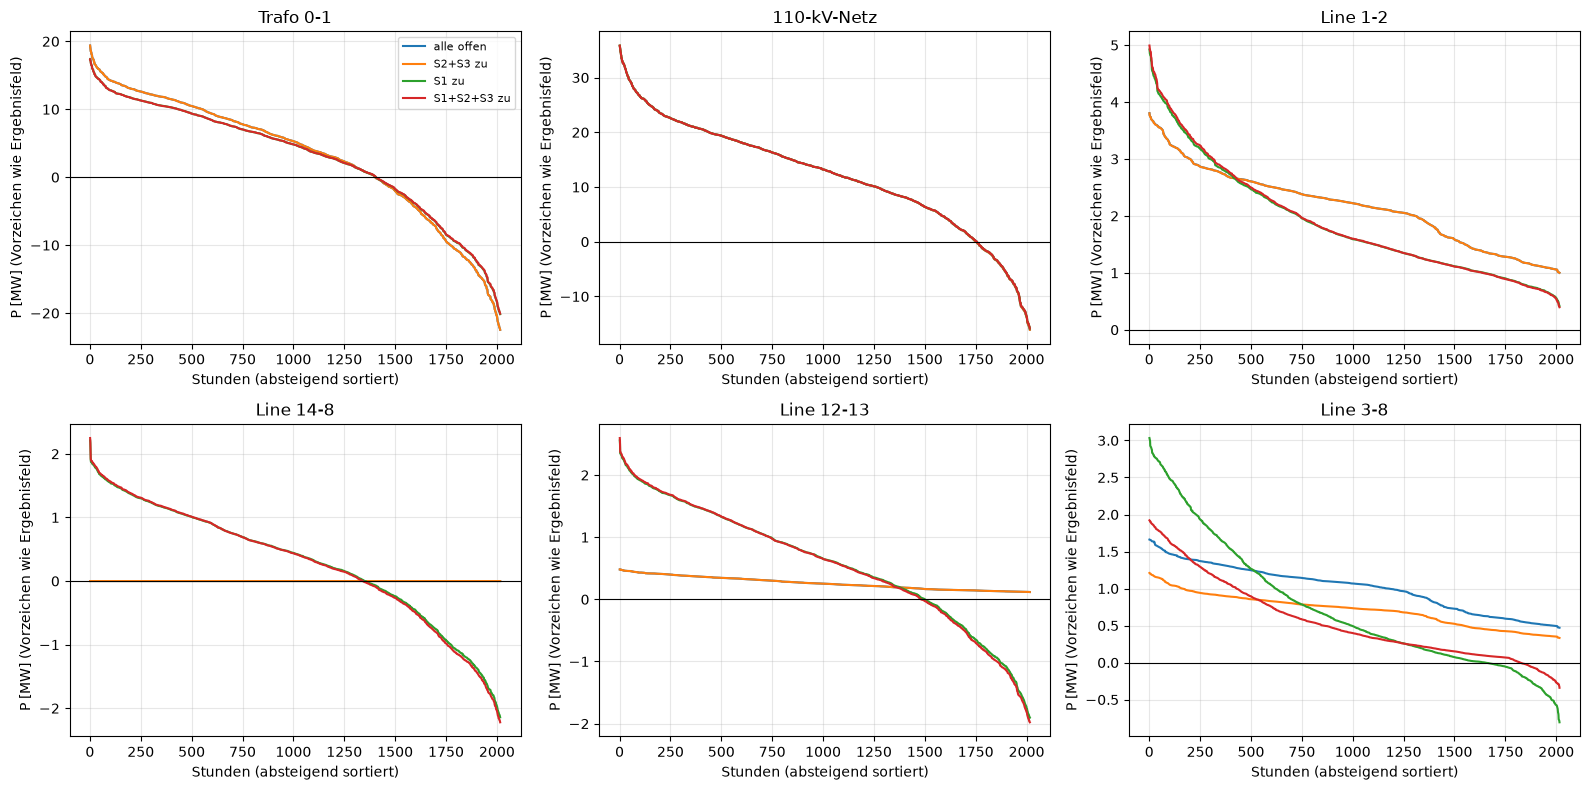

Stunden in Gegenrichtung


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,615,615,615,615,613,612,613,612
110-kV-Netz,263,263,263,263,261,261,261,261
Line 1-2,0,0,0,0,0,0,0,0
Line 14-8,0,0,0,0,664,678,664,676
Line 12-13,0,0,0,0,515,538,519,534
Line 3-8,0,0,0,0,364,428,137,193


Energie in Gegenrichtung [MWh]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,5154.1,5154.5,5154.1,5154.6,4605.1,4576.6,4596.2,4576.7
110-kV-Netz,1567.2,1567.3,1567.2,1567.4,1535.2,1534.4,1534.7,1534.3
Line 1-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Line 14-8,0.0,0.0,0.0,0.0,523.7,553.2,532.4,553.0
Line 12-13,0.0,0.0,0.0,0.0,372.2,396.4,379.9,396.6
Line 3-8,0.0,0.0,0.0,0.0,81.0,65.4,18.4,24.1


größter Fluss in Gegenrichtung [MW]


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Trafo 0-1,22.46,22.46,22.46,22.46,20.16,20.09,20.13,20.08
110-kV-Netz,16.09,16.09,16.09,16.09,15.86,15.86,15.86,15.86
Line 1-2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Line 14-8,0.00,0.00,0.00,0.00,2.14,2.21,2.18,2.22
Line 12-13,0.00,0.00,0.00,0.00,1.90,1.97,1.94,1.98
Line 3-8,0.00,0.00,0.00,0.00,0.81,0.55,0.38,0.34


In [ ]:
DL_ELEMENTE = ["Trafo 0-1", "110-kV-Netz", "Line 1-2", "Line 14-8", "Line 12-13", "Line 3-8"]
DL_ZUSTAENDE = ["000", "011", "100", "111"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, el in zip(axes.flat, DL_ELEMENTE):
    for k in DL_ZUSTAENDE:
        werte = np.sort(P[k][el].to_numpy())[::-1]
        ax.plot(np.arange(1, len(werte) + 1), werte, label=spalten[k])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(el)
    ax.set_xlabel("Stunden (absteigend sortiert)")
    ax.set_ylabel("P [MW] (Vorzeichen wie Ergebnisfeld)")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

zeilen = {}
for el in DL_ELEMENTE:
    for k in alle:
        x = P[k][el]
        haupt = 1 if (x > SCHWELLE).sum() >= (x < -SCHWELLE).sum() else -1
        gegen = x[np.sign(x) == -haupt]
        gegen = gegen[gegen.abs() >= SCHWELLE]
        zeilen.setdefault(el, {})[spalten[k]] = (len(gegen), gegen.abs().sum(), gegen.abs().max() if len(gegen) else 0.0)
for titel, i, nachkomma in (("Stunden in Gegenrichtung", 0, 0), ("Energie in Gegenrichtung [MWh]", 1, 1),
                            ("größter Fluss in Gegenrichtung [MW]", 2, 2)):
    print(titel)
    display(plots.table(pd.DataFrame({el: {z: v[i] for z, v in d.items()} for el, d in zeilen.items()}).T.astype(float), decimals=nachkomma))

**Ergebnis Dauerlinien:**

| Element | Gegenrichtung ohne S1 | Gegenrichtung mit S1 |
|---|---|---|
| Trafo 0-1 | 615 h, 5154 MWh, bis 22,5 MW | 612–613 h, 4577–4605 MWh, bis 20,2 MW |
| 110-kV-Netz | 263 h, 1567 MWh, bis 16,1 MW | 261 h, rund 1535 MWh, bis 15,9 MW |
| Line 14-8 (Kupplung) | – (offen) | 664–678 h, 524–553 MWh, bis 2,2 MW |
| Line 12-13 | keine | 515–538 h, 372–397 MWh, bis 2,0 MW |
| Line 3-8 | keine | 137–428 h, 18–81 MWh, bis 0,8 MW |
| Line 1-2 | keine | keine |

- **Häufigkeit:** Trafo 0-1 speist in fast einem Drittel der Stunden zurück, das 110-kV-Netz in 13 %. Die Dauerlinien laufen zur Rückspeisung hin steil nach unten: Wenige Stunden mit Starkwind bringen sehr hohe Rückspeisung.
- **Energie:** In 12 Wochen fließen über Trafo 0-1 rund 5,2 GWh zurück, ins 110-kV-Netz 1,6 GWh. Hochgerechnet auf ein Jahr (Faktor 8760 / 2016 ≈ 4,3) sind das etwa 22 bzw. 7 GWh.
- **Wirkung von S1:** S1 senkt die Rückspeisung über Trafo 0-1 um etwa 11 %, weil Abgang 2 einen Teil des Windstroms aufnimmt. Dafür kehren sich die Kupplung und Abgang 2 in etwa einem Viertel bis einem Drittel der Stunden um. Die Flüsse dort sind mit höchstens 2,2 MW klein.
- **Line 1-2** kehrt sich nie um, auch mit S1 nicht. Mit S1 wird ihre Dauerlinie aber steiler: Bei Starkwind trägt sie bis 5 MW (fast 100 %), bei wenig Wind weniger als ohne S1.
- **Line 3-8** kehrt sich mit S1 allein am häufigsten um. Mit S2 kaum noch, weil die Masche über Line 6-7 einen zweiten Weg anbietet.

## 8 Räumliche Darstellung der Flüsse

Netzplan mit Flusspfeilen in zwei Stunden, in denen sich mit geschlossenem S1 Leitungen umkehren, jeweils links ohne und rechts mit S1:

- **viel Wind:** Stunde mit der stärksten Rückspeisung ins 110-kV-Netz
- **viel PV, wenig Wind:** Stunde mit dem stärksten Fluss in Gegenrichtung auf Line 3-8 (mit S1)

viel Wind: 19.12. 02:00 – Wind 29.5 MW, PV 0.0 MW, Last 13.3 MW


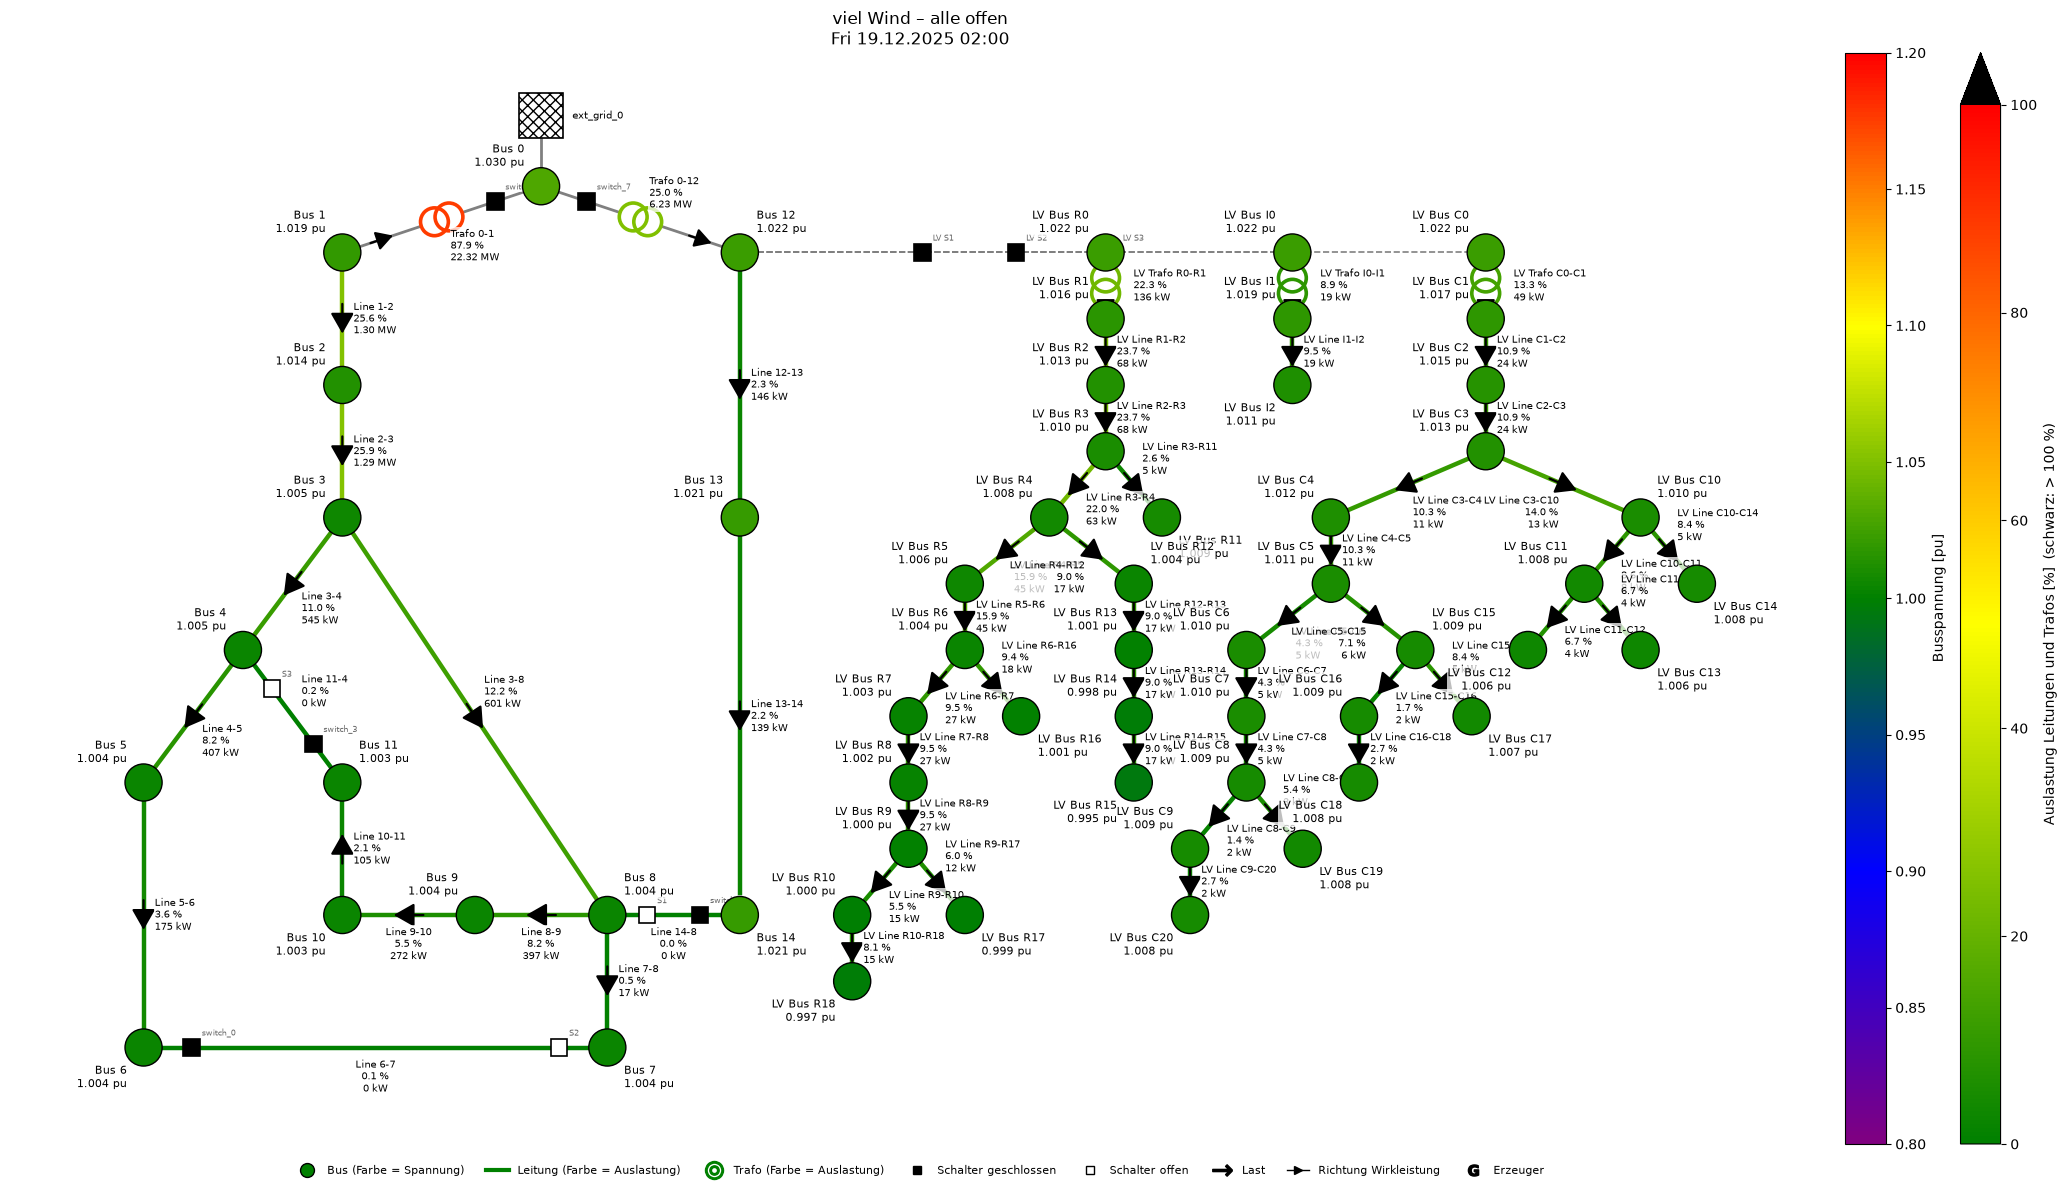

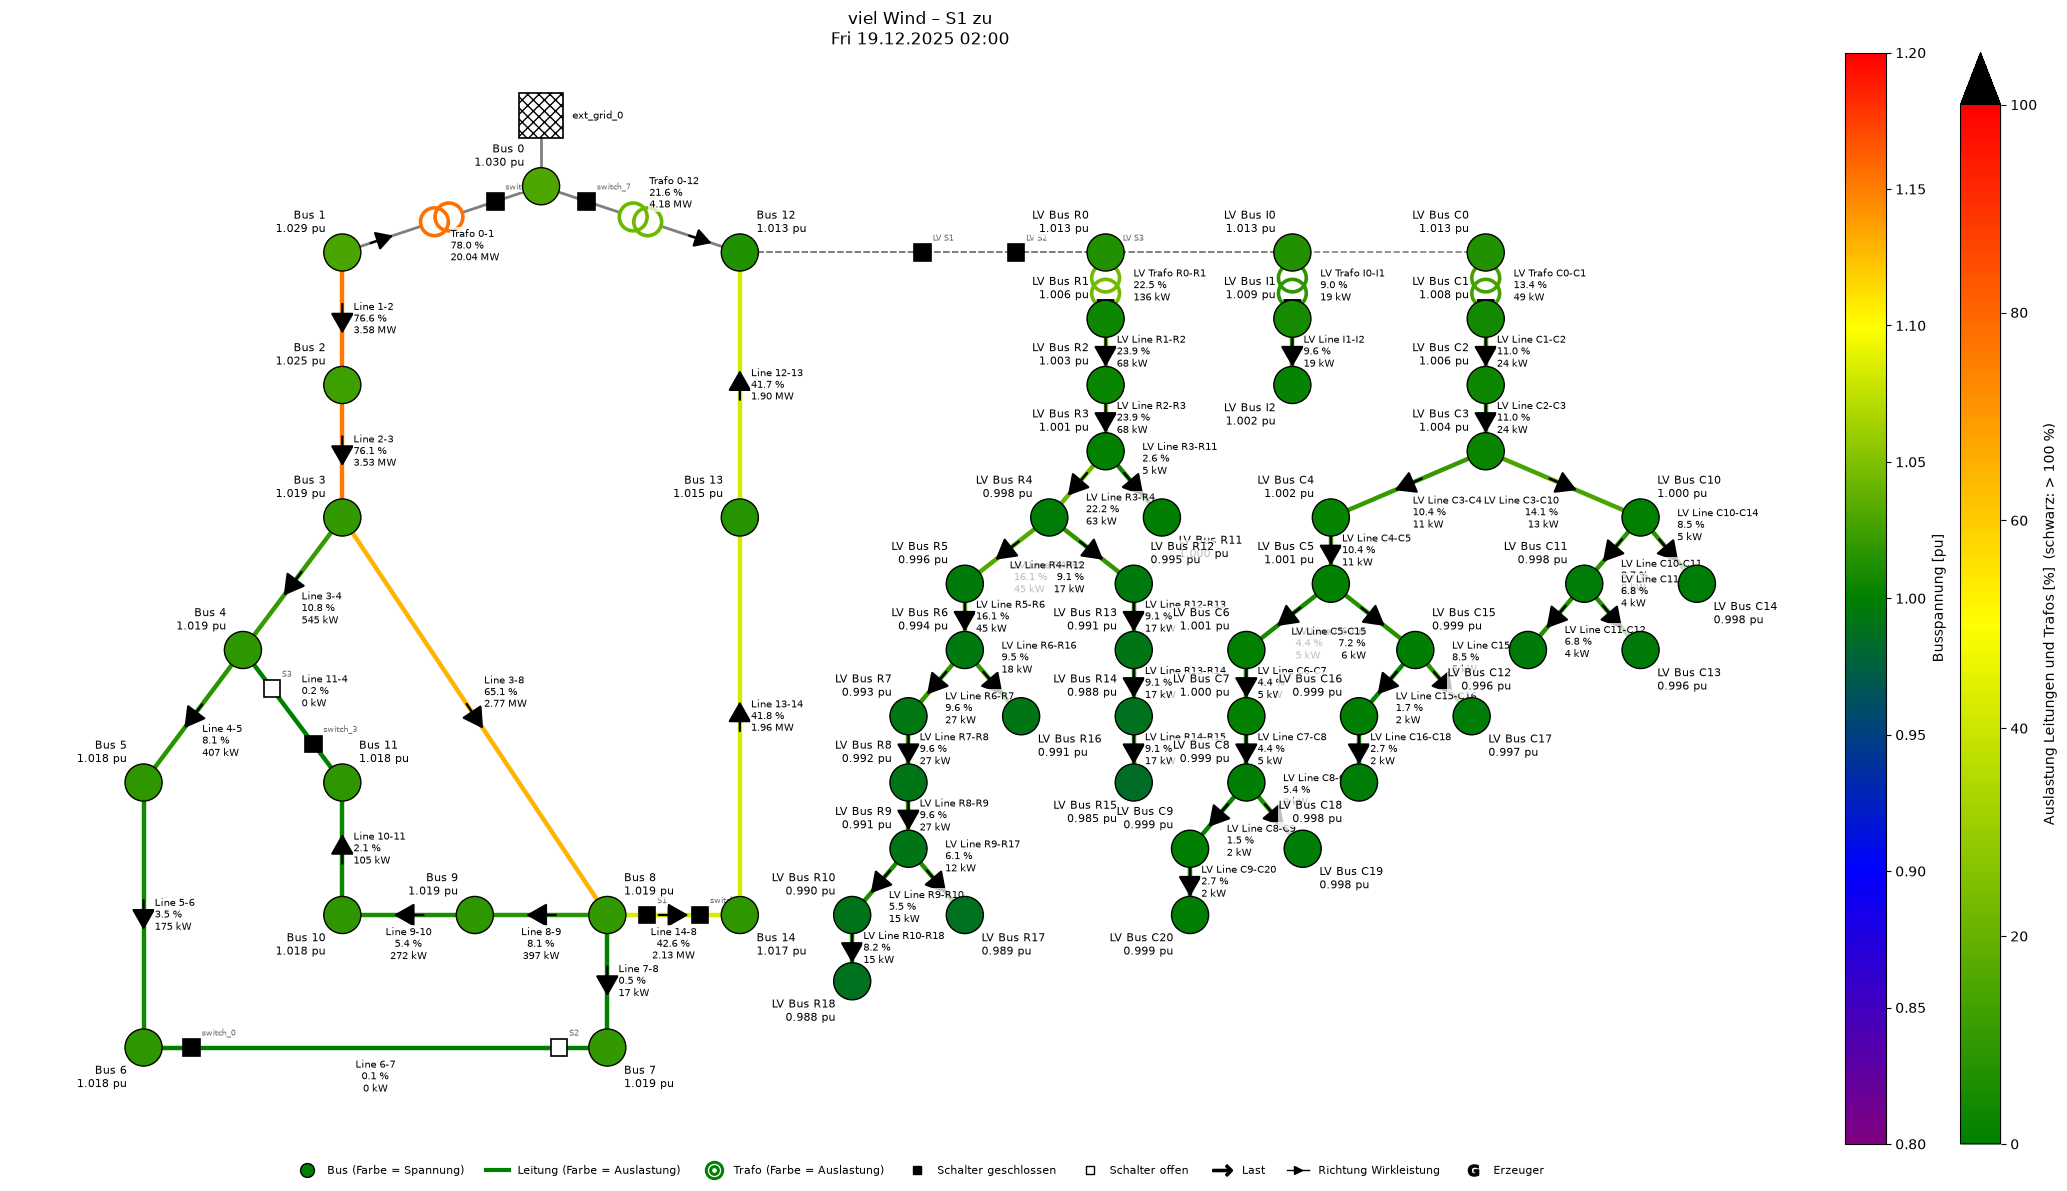

viel PV, wenig Wind: 09.03. 12:00 – Wind 0.0 MW, PV 7.4 MW, Last 31.2 MW


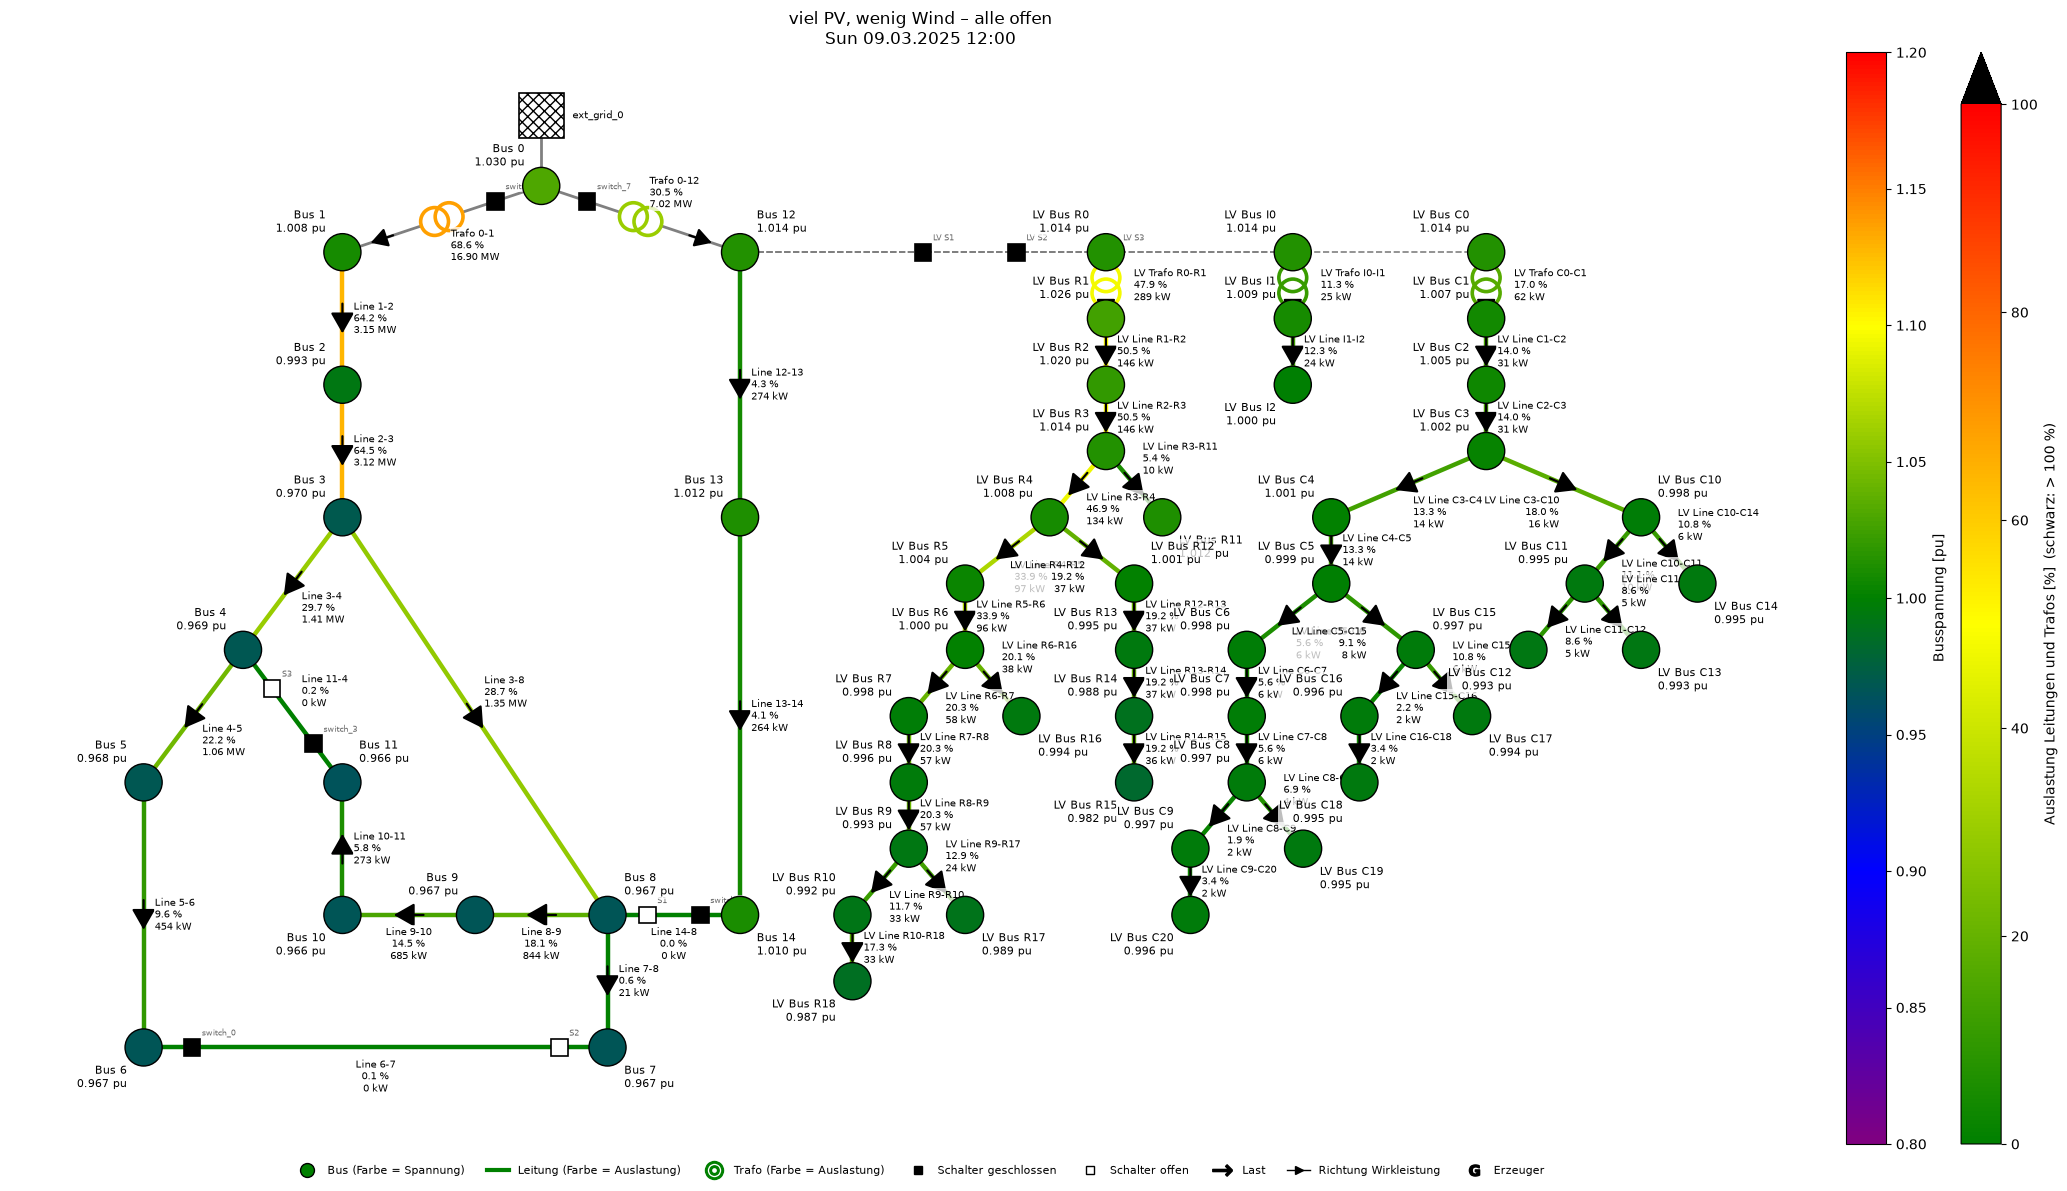

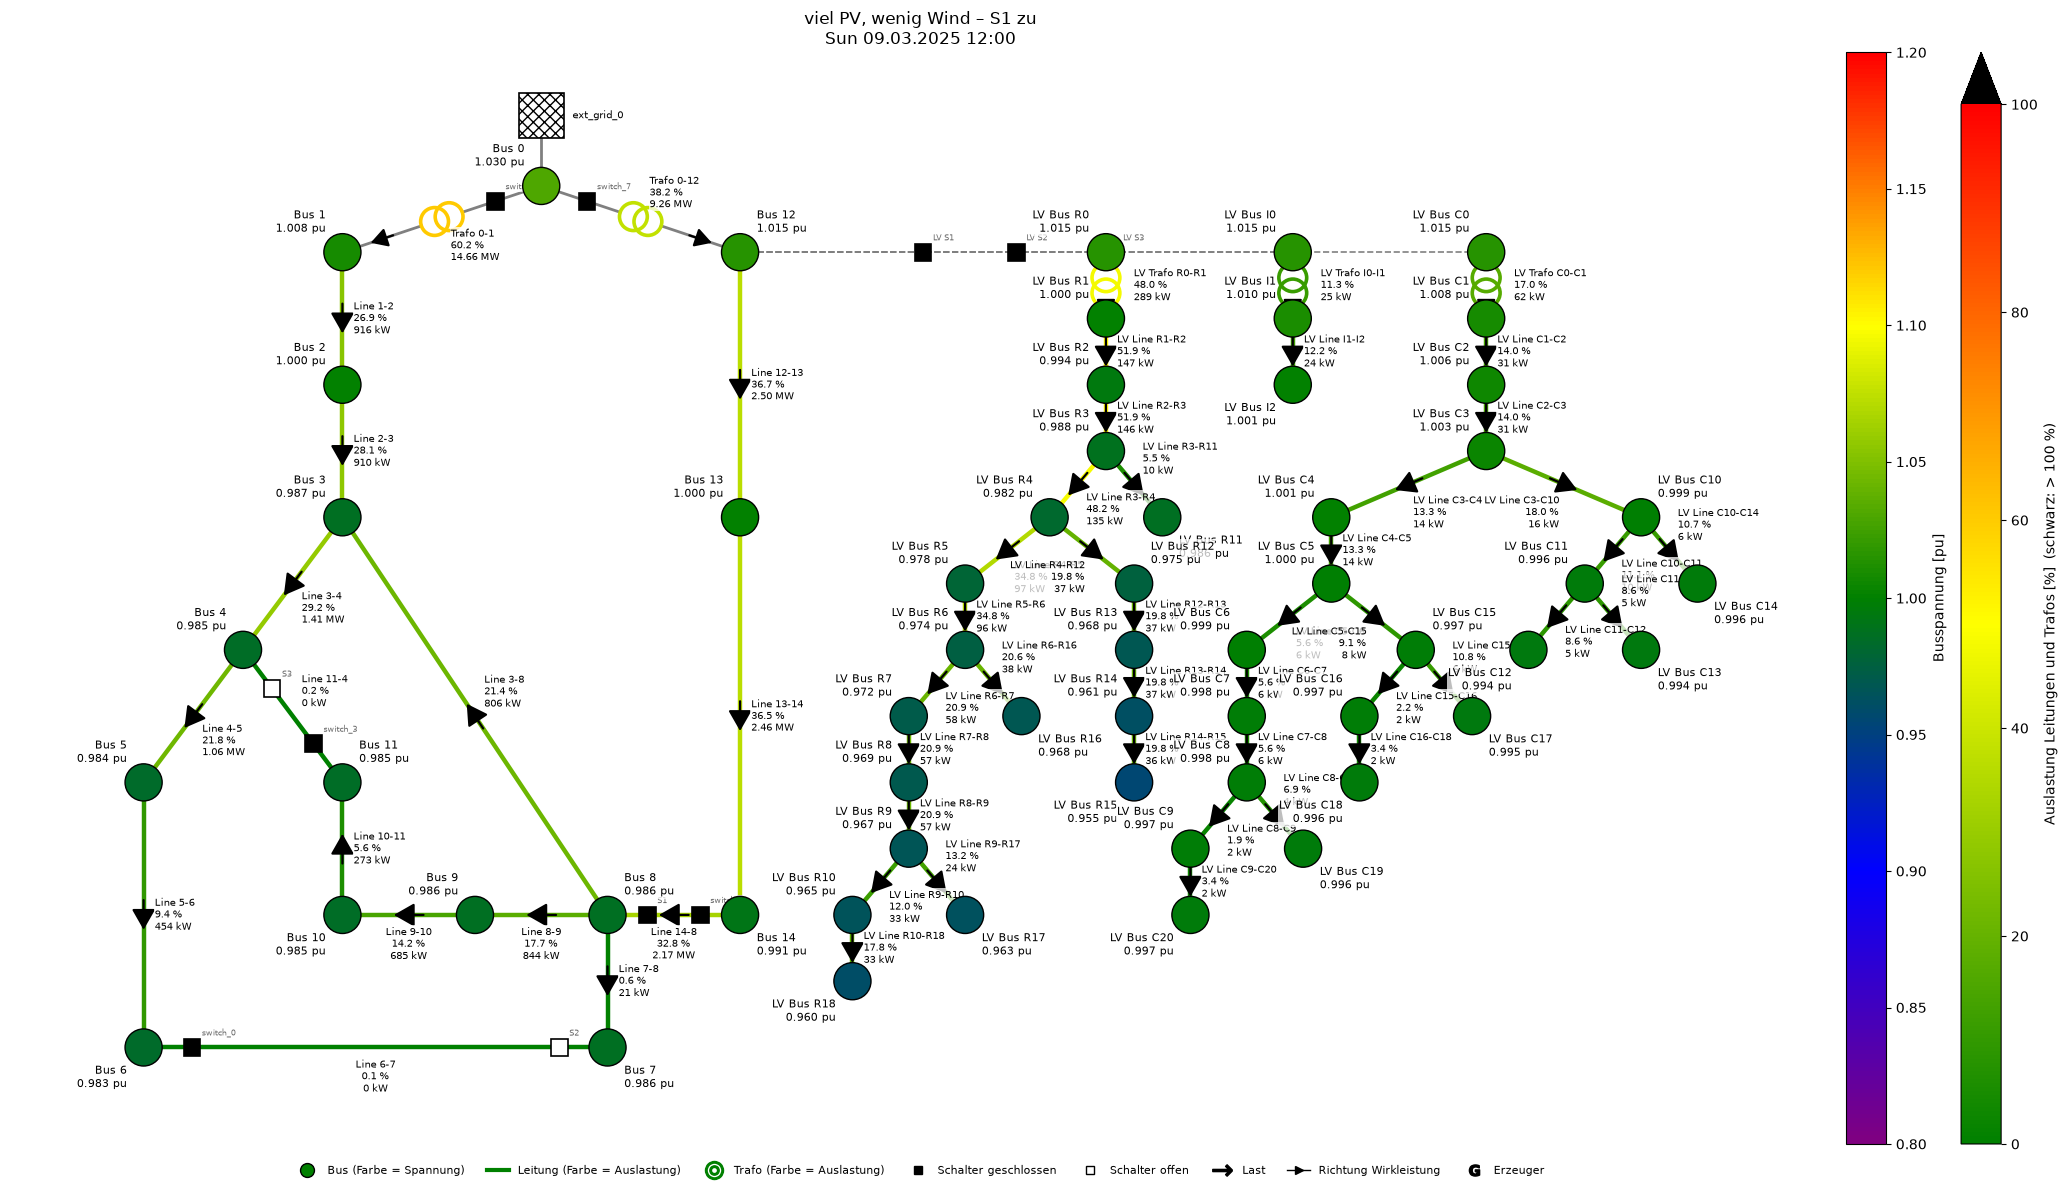

In [ ]:
h_wind = P["100"]["110-kV-Netz"].idxmin()
h_pv = P["100"]["Line 3-8"].idxmin()
for titel, h in (("viel Wind", h_wind), ("viel PV, wenig Wind", h_pv)):
    r1 = alle["100"].results
    print(f"{titel}: {h:%d.%m. %H:%M} – Wind {r1.sgen_p_mw.at[h, 'Windpark']:.1f} MW, PV {r1.sgen_p_mw.at[h, 'PV-Freifläche']:.1f} MW, "
          f"Last {r1.load_p_mw.loc[h].sum():.1f} MW")
    for k in ("000", "100"):
        alle[k].createDiagram(Diagram.NETWORK, time=[h], elements=False, title=f"{titel} – {spalten[k]}")

**Was die Netzpläne zeigen:**

- **Viel Wind** (19.12., 2 Uhr, 29,5 MW Wind, 13,3 MW Last):
  - **ohne S1:** Der Windpark versorgt Abgang 1, der Überschuss fließt über Trafo 0-1 zurück ins 110-kV-Netz (Pfeil am Trafo nach oben). Alle Leitungen behalten ihre Richtung.
  - **mit S1:** Ein Teil des Windstroms fließt durch Abgang 1 bis Bus 8 und über S1 weiter in Abgang 2. Die Pfeile auf Line 14-8, 13-14 und 12-13 zeigen jetzt zu Bus 12, Trafo 0-12 wird entlastet.
- **Viel PV, wenig Wind** (09.03., 12 Uhr, 7,4 MW PV, kein Wind, 31,2 MW Last):
  - **ohne S1:** Beide Abgänge werden von ihrem Trafo versorgt.
  - **mit S1:** Abgang 2, durch die PV entlastet, versorgt über S1 Bus 8 bis 11 und über Line 3-8 auch Bus 3 mit. Der Pfeil auf Line 3-8 zeigt zu Bus 3 (0,8 MW). Trafo 0-1 trägt deutlich weniger (60 %), Trafo 0-12 mehr.
- **Folge:** Mit S1 hängt die Flussrichtung im MS-Netz davon ab, an welchem Ende gerade mehr erzeugt wird.

## 9 Rückspeisung im Ortsnetz

Im Ortsnetz sind die PV-Haushalte mit den BDEW-Profilen P25 und S25 abgebildet. Das sind Netzbezugsprofile: Sie beschreiben, was ein Haushalt mit PV-Anlage (und Speicher) noch aus dem Netz bezieht, aber nicht, was er einspeist (BDEW-Anwendungshilfe, Datengrundlage). Eine Einspeisung ins Ortsnetz ist damit nicht abgebildet. Kleinster Fluss über die Ortsnetztrafos in allen Schaltzuständen:

In [ ]:
pd.DataFrame({spalten[k]: P[k][list(ONT.values())].min() for k in alle}).round(4)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
LV Trafo R0-R1,0.0900,0.0900,0.0900,0.0900,0.0900,0.0900,0.0900,0.0900
LV Trafo I0-I1,0.0159,0.0159,0.0159,0.0159,0.0159,0.0159,0.0159,0.0159
LV Trafo C0-C1,0.0400,0.0400,0.0400,0.0400,0.0400,0.0400,0.0400,0.0400


**Befund:** Über alle drei Ortsnetztrafos fließt in jeder Stunde und in jedem Schaltzustand Leistung vom MS- ins NS-Netz (mindestens 90 kW, 16 kW bzw. 40 kW). Im Ortsnetz tritt keine Lastflussumkehr auf. Die Folgen sind:

- Die rONT regeln nur gegen Unterspannung, ihre Stellung −1 bzw. −2 hebt die Spannung an (Abschnitt 6). Eine Regelung gegen Überspannung durch Rückspeisung kommt nicht vor.
- Die Lastflussumkehr im MS-Netz wirkt nur indirekt über die Spannung an Bus 12 auf das Ortsnetz.

**Einordnung:** Das ist eine Folge der Modellierung, keine Eigenschaft realer Ortsnetze. P25 und S25 bilden den verbleibenden Bezug von PV-Haushalten ab, nicht deren Einspeisung. In einem realen Wohngebiet mit vielen Dachanlagen würde die Leistung an sonnigen Mittagen ins MS-Netz zurückfließen. Der rONT müsste dann auch nach oben (Stufe +1, +2) regeln. Die Regelung dafür ist vorhanden und wurde in Teil 3b, Abschnitt 5.2 mit einem Überspannungstest geprüft.

## 10 Zusatz: Ausfall eines 110/20-kV-Transformators

Nicht Teil des Arbeitsauftrags. Was passiert, wenn Trafo 0-1 oder Trafo 0-12 für die ganzen 12 Wochen ausfällt? Drei Varianten je Trafo:

- **S1 offen:** Der Abgang des ausgefallenen Trafos ist vom Netz getrennt. Die Erzeugung an seiner Sammelschiene ist mit abgetrennt und kann nicht einspeisen (Inselbetrieb ist nicht vorgesehen).
- **S1 zu:** Der Abgang wird über S1 aus dem anderen Trafo versorgt. Windpark bzw. PV-Anlage speisen weiter ein, sitzen jetzt aber am **Ende** eines langen Wegs.
- **S1 zu, Erzeuger aus:** wie vorher, aber der Windpark bzw. die PV-Anlage ist abgeschaltet (so sieht es der Backup-Plan aus Teil 4a vor).

In Stunden, in denen der Lastfluss nicht konvergiert, kann das Netz den Betriebspunkt physikalisch nicht halten (Spannungskollaps). Diese Stunden werden gezählt und fehlen in den übrigen Kennwerten.

In [ ]:
AUSFALL = {
    "Trafo 0-1 aus · S1 offen": ("Trafo 0-1", False, None),
    "Trafo 0-1 aus · S1 zu": ("Trafo 0-1", True, None),
    "Trafo 0-1 aus · S1 zu · Windpark aus": ("Trafo 0-1", True, "Windpark"),
    "Trafo 0-12 aus · S1 offen": ("Trafo 0-12", False, None),
    "Trafo 0-12 aus · S1 zu": ("Trafo 0-12", True, None),
    "Trafo 0-12 aus · S1 zu · PV aus": ("Trafo 0-12", True, "PV-Freifläche"),
}
ausfall = {}
for i, (titel, (trafo, s1, erzeuger)) in enumerate(AUSFALL.items(), 1):
    s = basis.copy(f"w4_t5_trafoausfall_{i}", overwrite=True)
    s.changeParameter(trafo, "in_service", False)
    if s1:
        s.changeParameter("S1", "closed", True)
    if erzeuger:
        s.changeParameter(erzeuger, "in_service", False)
    s.runSimulation(controllers=lv_regler(s.net))
    ausfall[titel] = s

Hinweis: 11 Busse sind nicht versorgt (z. B. ['Bus 1', 'Bus 2', 'Bus 3', 'Bus 4', 'Bus 5']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Simulation 'w4_t5_trafoausfall_1': 2016 Lastflüsse in 66 s, nicht konvergiert: 0
Simulation 'w4_t5_trafoausfall_2': 2016 Lastflüsse in 80 s, nicht konvergiert: 704 (als NaN gespeichert)
Simulation 'w4_t5_trafoausfall_3': 2016 Lastflüsse in 77 s, nicht konvergiert: 1511 (als NaN gespeichert)
Hinweis: 46 Busse sind nicht versorgt (z. B. ['Bus 12', 'Bus 13', 'Bus 14', 'LV Bus R14', 'LV Bus R15']); ihre Ergebnisse sind NaN. Bei einem Ausfall mit Wiederversorgung ist das der Zustand vor dem Schließen der Trennstelle.
Simulation 'w4_t5_trafoausfall_4': 2016 Lastflüsse in 56 s, nicht konvergiert: 0
Simulation 'w4_t5_trafoausfall_5': 2016 Lastflüsse in 72 s, nicht konvergiert: 1370 (als NaN gespeichert)
Simulation 'w4_t5_trafoausfall_6': 2016 Lastflüsse in 73 s, nicht konvergiert: 154

In [ ]:
def ausfall_kennwerte(s):
    rr = s.results
    ok = rr.converged.astype(bool) if hasattr(rr, "converged") else rr.vm_pu.notna().any(axis=1)
    vm = rr.vm_pu.loc[ok]
    ms = vm[MS_BUSSE]
    ll = rr.line_loading.loc[ok, [c for c in rr.line_loading if c.startswith("Line")]]
    tl = rr.trafo_loading.loc[ok, ["Trafo 0-1", "Trafo 0-12"]]
    return {"Stunden konvergiert": int(ok.sum()),
            "Stunden nicht konvergiert": int((~ok).sum()),
            "Stunden mit nicht versorgten MS-Bussen": int(ms.isna().any(axis=1).sum()),
            "U min MS [pu]": ms.min().min(), "U max MS [pu]": ms.max().max(),
            "Stunden U MS > 1,10 pu": int((ms.max(axis=1) > 1.10).sum()),
            "Stunden U MS < 0,90 pu": int((ms.min(axis=1) < 0.90).sum()),
            "U min NS [pu]": vm[g["NS"]].min().min(), "U max NS [pu]": vm[g["NS"]].max().max(),
            "Leitung max MS [%]": ll.max().max(), "am stärksten belastet": ll.max().idxmax() if ll.size else "",
            "Stunden Leitung MS > 100 %": int((ll.max(axis=1) > 100).sum()),
            "Trafo max HS/MS [%]": tl.max().max(), "Stunden Trafo > 100 %": int((tl.max(axis=1) > 100).sum()),
            "Stunden Rückspeisung 110 kV": int((rr.ext_grid_p_mw.squeeze().loc[ok] < -SCHWELLE).sum())}

a_tab = pd.DataFrame({"Normalzustand": ausfall_kennwerte(normal), **{t: ausfall_kennwerte(s) for t, s in ausfall.items()}})
plots.table(a_tab, decimals=3)

,Normalzustand,Trafo 0-1 aus · S1 offen,Trafo 0-1 aus · S1 zu,Trafo 0-1 aus · S1 zu · Windpark aus,Trafo 0-12 aus · S1 offen,Trafo 0-12 aus · S1 zu,Trafo 0-12 aus · S1 zu · PV aus
Stunden konvergiert,2016,2016,1312,505,2016,646,470
Stunden nicht konvergiert,0,0,704,1511,0,1370,1546
Stunden mit nicht versorgten MS-Bussen,0,2016,0,0,2016,0,0
U min MS [pu],0.950828,1.000894,0.518749,0.542434,0.950828,0.524311,0.550865
U max MS [pu],1.025020,1.024085,1.247383,1.012906,1.025020,1.014239,1.014239
"Stunden U MS > 1,10 pu",0,0,272,0,0,0,0
"Stunden U MS < 0,90 pu",0,0,518,505,0,646,470
U min NS [pu],0.950021,0.950021,0.933321,0.950978,nan,0.405549,0.522127
U max NS [pu],1.025951,1.025951,1.029668,1.009698,nan,0.878858,0.866610
Leitung max MS [%],78.490900,7.952733,382.175428,286.646548,78.490899,313.734954,306.742475


**Trafo 0-1 aus, S1 zu:** Spannung entlang des Wegs vom verbleibenden Trafo bis zum Windpark (Bus 12 → 13 → 14 → 8 → 3 → 2 → 1) und Windleistung in der Woche mit der höchsten Windeinspeisung:

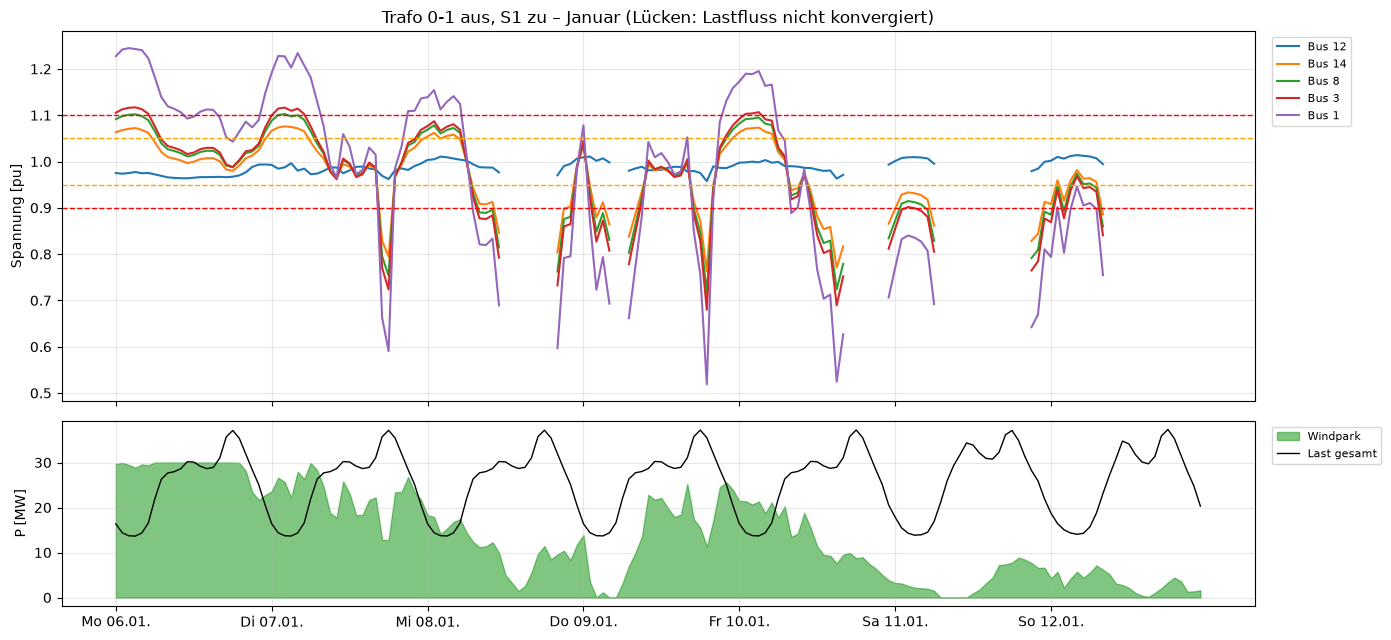

In [ ]:
s = ausfall["Trafo 0-1 aus · S1 zu"]
rr = s.results
woche = rr.info["month"].to_numpy()
m = woche[np.argmax(rr.sgen_p_mw["Windpark"].fillna(0).to_numpy())]
idx = rr.info.index[rr.info["month"] == m]
WEG = ["Bus 12", "Bus 14", "Bus 8", "Bus 3", "Bus 1"]
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.arange(len(idx))
for bus in WEG:
    axes[0].plot(x, rr.vm_pu.loc[idx, bus], label=bus)
for v, farbe in ((0.90, "red"), (0.95, "orange"), (1.05, "orange"), (1.10, "red")):
    axes[0].axhline(v, color=farbe, ls="--", lw=1)
axes[0].set_ylabel("Spannung [pu]")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[0].set_title(f"Trafo 0-1 aus, S1 zu – {Month[m].label} (Lücken: Lastfluss nicht konvergiert)")
axes[1].fill_between(x, rr.sgen_p_mw.loc[idx, "Windpark"], color="tab:green", alpha=0.6, label="Windpark")
axes[1].plot(x, rr.load_p_mw.loc[idx].sum(axis=1), color="black", lw=1, label="Last gesamt")
axes[1].set_ylabel("P [MW]")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
tage = [i for i in range(0, len(idx), 24)]
axes[1].set_xticks(tage, [f"{TAGE[idx[i].weekday()][:2]} {idx[i]:%d.%m.}" for i in tage])
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

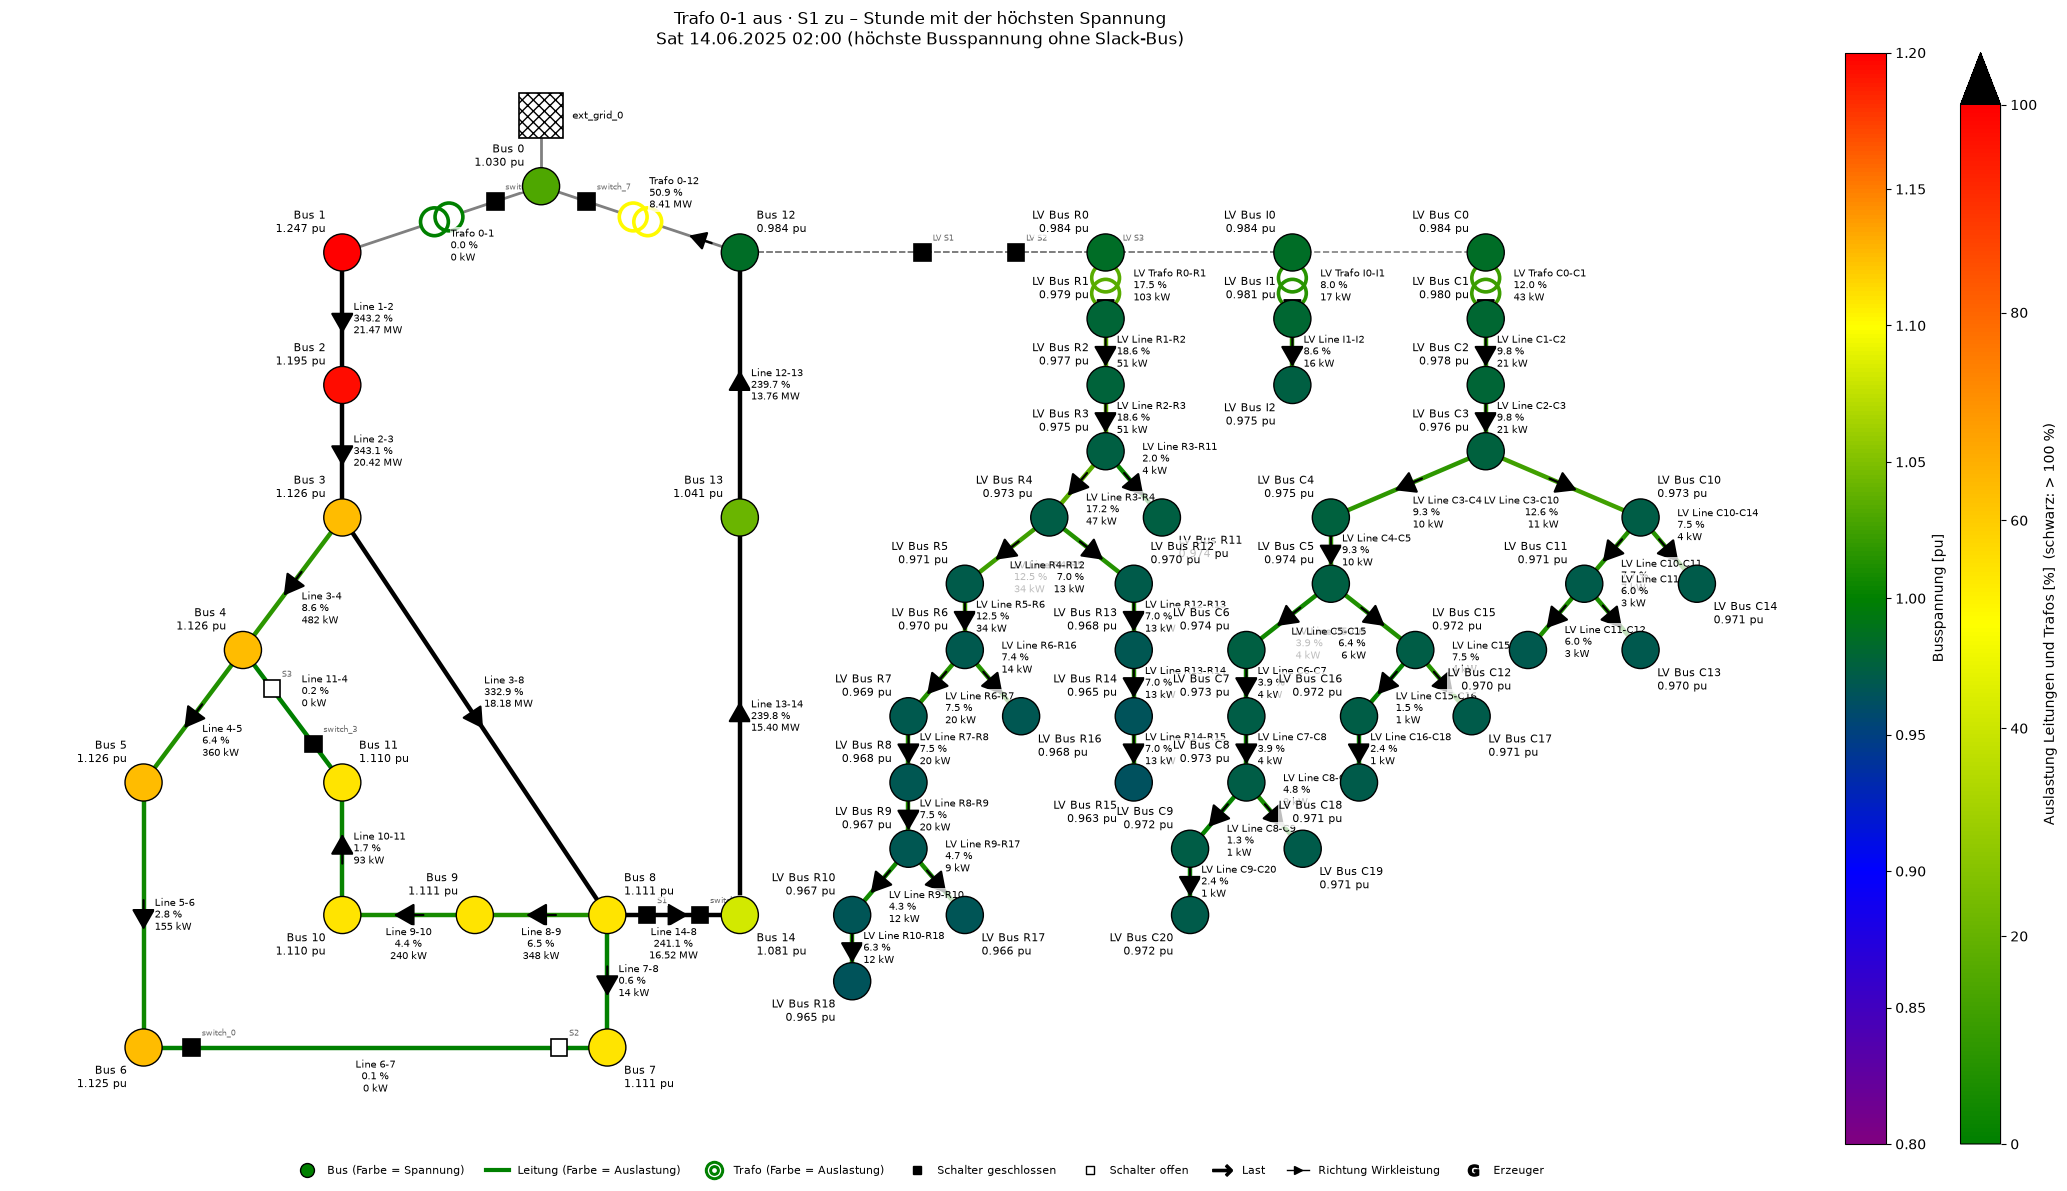

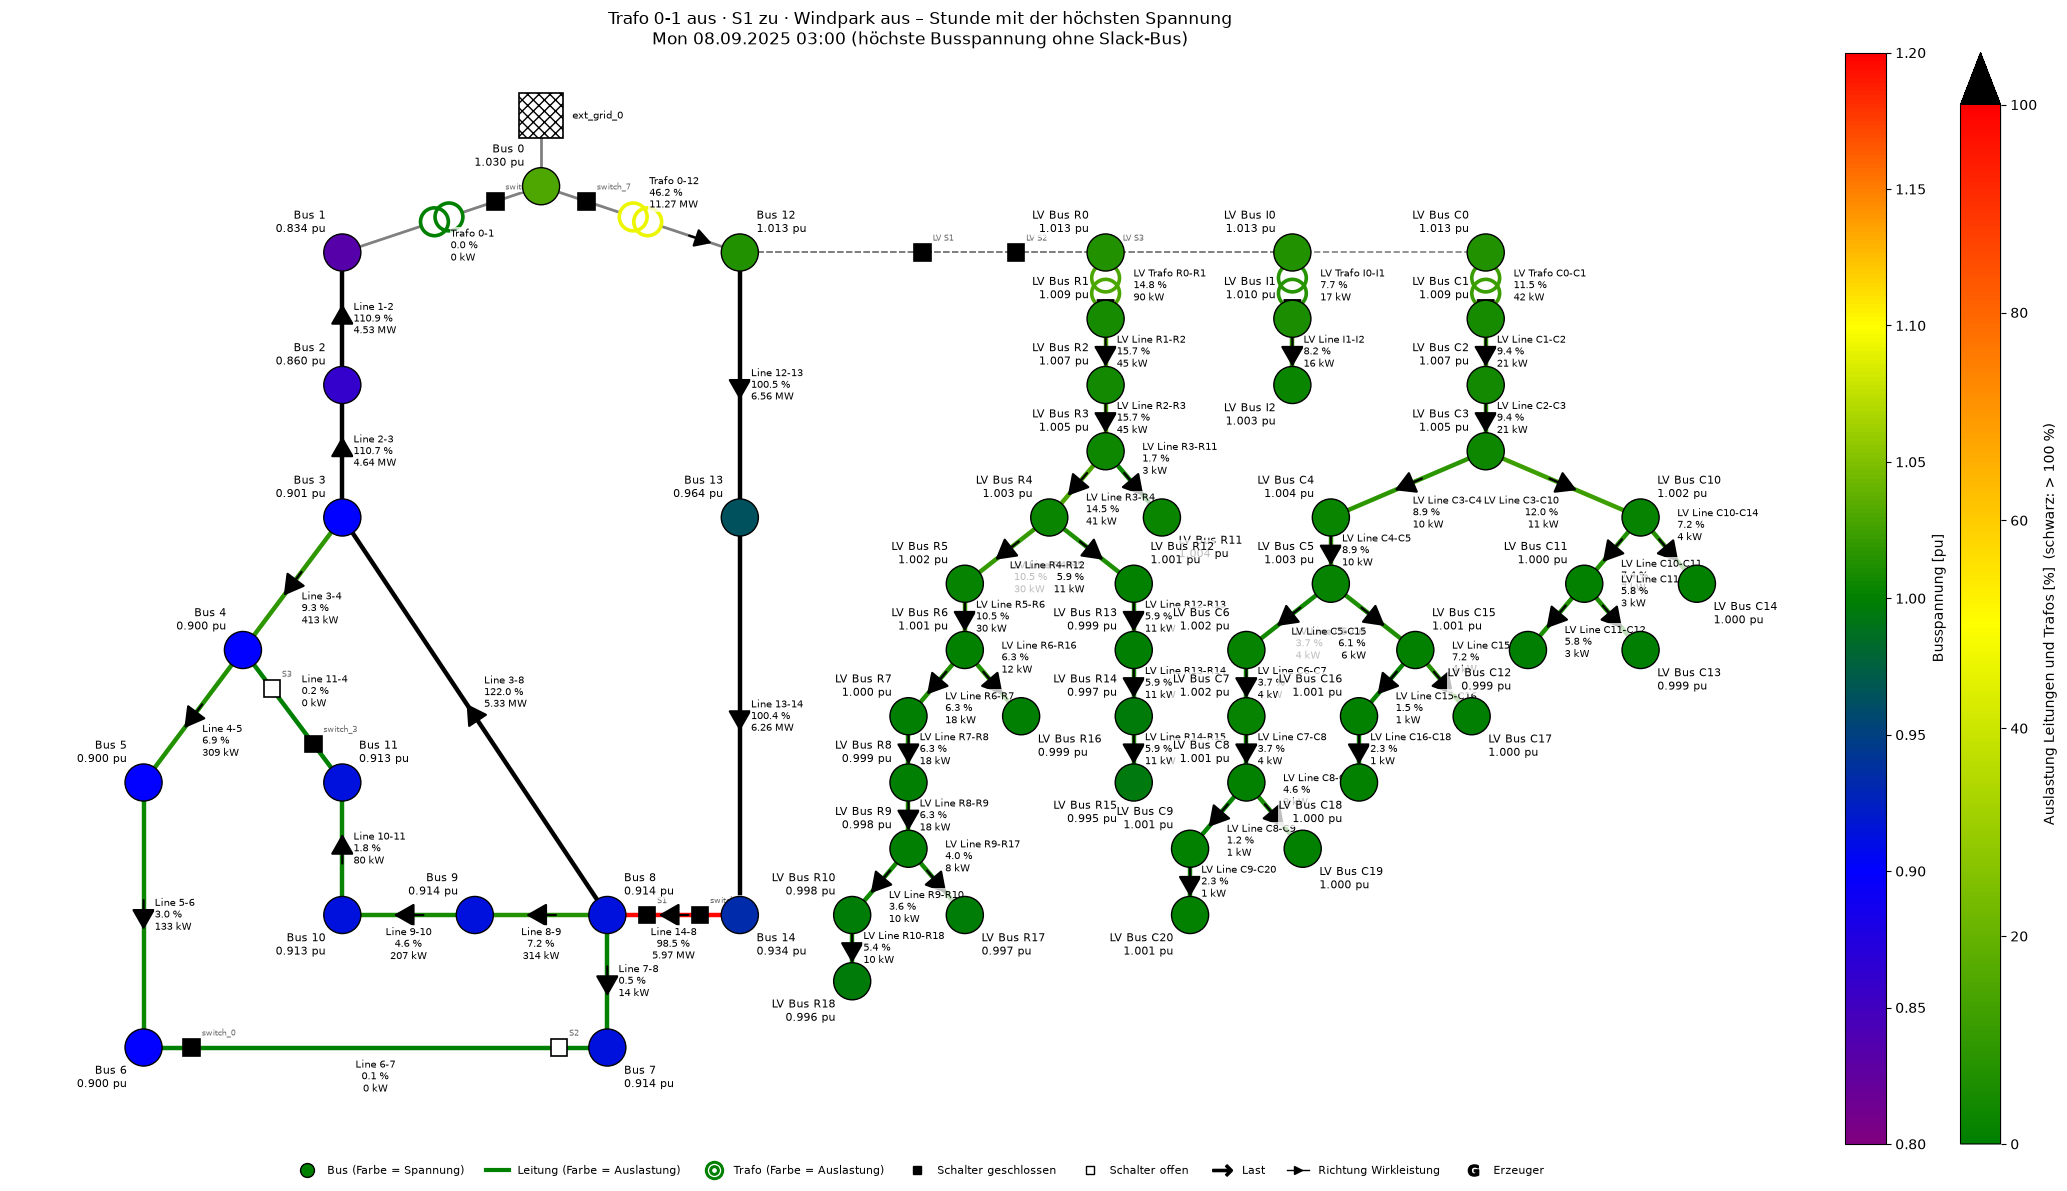

In [ ]:
for titel in ("Trafo 0-1 aus · S1 zu", "Trafo 0-1 aus · S1 zu · Windpark aus"):
    ausfall[titel].createDiagram(Diagram.NETWORK, time=["max"], elements=False, title=f"{titel} – Stunde mit der höchsten Spannung")

**Ergebnis Trafoausfall:**

- **S1 offen:** Der Abgang des ausgefallenen Trafos ist in allen Stunden ohne Versorgung (Trafo 0-1: Bus 1 bis 11; Trafo 0-12: Bus 12 bis 14 und das ganze Ortsnetz). Der übrige Teil läuft normal weiter. Fällt Trafo 0-12 aus, fließt der Windüberschuss nicht mehr teilweise in Abgang 2, sondern vollständig ins 110-kV-Netz: Rückspeisung in 615 statt 263 Stunden.
- **Trafo 0-1 aus, S1 zu, Windpark speist weiter:** Deine Vermutung stimmt: Der Windpark sitzt jetzt am Ende eines langen Wegs (Bus 12 → 13 → 14 → 8 → 3 → 2 → 1), hebt dort die Spannung an und kehrt die Flüsse um. Das passiert aber weit über die Grenzen hinaus:
  - In 272 Stunden liegt die Spannung über 1,10 pu, an Bus 1 bis 1,25 pu. Line 1-2 wird mit bis zu 382 % ausgelastet, Trafo 0-12 mit bis zu 130 %. In 200 Stunden fließt Windstrom über den ganzen Weg und Trafo 0-12 ins 110-kV-Netz.
  - Bei wenig Wind und hoher Last kehrt sich das Bild um: Die Spannung bricht bis 0,52 pu ein, und in 704 Stunden konvergiert der Lastfluss gar nicht (Lücken im Diagramm).
  - Nur in 297 von 2016 Stunden (15 %) liegen alle Spannungen zwischen 0,90 und 1,10 pu und alle Auslastungen unter 100 %. Das sind die Stunden, in denen Wind und Last von Abgang 1 etwa gleich groß sind und kaum Leistung über den langen Weg fließen muss.
- **Trafo 0-1 aus, S1 zu, Windpark aus:** Ohne Windpark muss die ganze Last von Abgang 1 über den langen Weg fließen. Das ist noch schlechter: In 1511 Stunden konvergiert der Lastfluss nicht, in allen übrigen liegt die Spannung unter 0,90 pu und Leitungen sind überlastet. Der Windpark hat in vielen Stunden einen Teil der Last vor Ort gedeckt.
- **Trafo 0-12 aus, S1 zu:** Abgang 2 und das Ortsnetz werden über Abgang 1 versorgt. In 1370 Stunden (mit PV) bzw. 1546 Stunden (ohne PV) konvergiert der Lastfluss nicht. In den übrigen Stunden fällt die NS-Spannung auf 0,41 bis 0,88 pu; das können die rONT mit zwei Stufen nicht ausgleichen.
- **Folgerung:** Der Ausfall eines 110/20-kV-Trafos lässt sich über S1 in keiner Variante beherrschen. Den Grund haben schon Teil 3b und 4a gezeigt: Die Kupplung am Ende der Abgänge kann nicht die Leistung eines ganzen Abgangs übertragen. Das Abschalten des Erzeugers verhindert zwar die Überspannung, aber nicht den Spannungseinbruch. Abhilfe wäre eine Kupplung direkt im Umspannwerk (Teil 4a, 6.3).

## 11 Ergebnis Lastflussumkehr

**Wann und wo tritt Lastflussumkehr auf?**

- **Normalzustand:** nur an Trafo 0-1 (615 h) und an der 110-kV-Netzkuppelstelle (263 h), weil Windpark und PV-Anlage direkt an den Trafo-Sammelschienen einspeisen. MS-Leitungen und Ortsnetz behalten immer ihre Richtung.
- **Auslöser:** Wind. Trafo 0-1 kehrt sich um, sobald der Windpark mehr erzeugt, als Abgang 1 verbraucht; das 110-kV-Netz, sobald Wind und PV die gesamte Last übersteigen. Das tritt vor allem nachts und am Wochenende auf (geringe Last), abends kaum. Die PV-Anlage allein reicht nie.
- **Stärke:** bis 22,5 MW über Trafo 0-1 und 16,1 MW ins 110-kV-Netz; in 12 Wochen 5,2 bzw. 1,6 GWh.

**Einfluss der Schalterstellungen:**

- **S2 und S3** verteilen nur die Last innerhalb von Abgang 1 um. Die Leitungen am Ende der Stränge drehen ihre Richtung (Line 10-11 mit S3 dauerhaft), Spannungen und Auslastungen ändern sich um wenige Prozentpunkte, die rONT bleiben unbeeinflusst.
- **S1** führt zu Lastflussumkehr auf MS-Leitungen: auf der Kupplung und in Abgang 2 bei viel Wind, auf Line 3-8 bei PV ohne Wind. Abgang 1 wird um bis 2,6 Prozentpunkte angehoben, Abgang 2 um bis 1,9 Prozentpunkte abgesenkt. Trafo 0-1 wird um 10 Prozentpunkte entlastet, aber Line 1-2 erreicht bei Starkwind 99,6 %, und die Verluste steigen um 22 %.

**Folgen für Spannungen, Auslastungen und rONT-Regelung:**

- Alle Spannungen bleiben in allen Schaltzuständen im Planungsband. Die einzige kritische Auslastung ist Line 1-2 mit S1 bei Starkwind.
- Die rONT reagieren nur auf S1, weil S1 die Spannung an Bus 12 senkt: mehr Stufenschritte (Wohngebiet +28 %), teilweise Stufe −2, Schaltzeitpunkte früher und später als im Normalzustand. Der Industrie-rONT schaltet nur mit S1.
- Im Ortsnetz gibt es keine Rückspeisung, weil die PV-Haushalte als Bezugsprofile abgebildet sind. Die rONT regeln deshalb nie gegen Überspannung.

**Empfehlung für den Betrieb:** S1 im Normalbetrieb offen lassen (wie im Backup-Plan vorgesehen). Wenn S1 geschlossen wird, die Auslastung von Line 1-2 bei Starkwind überwachen. Beim Ausfall eines 110/20-kV-Trafos hilft S1 nicht.